# Clasificación temática de textos en Esperanto
### Práctica de programación · Minería de Textos · 4º INF · 2026/2027

**Integrantes:** _(completar con los nombres del equipo)_

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gonvt/Mineria-de-textos/blob/main/notebooks/clasificacion_esperanto.ipynb)

En este cuaderno se construye, de principio a fin, un sistema que clasifica
textos en **Esperanto** según el **deporte** del que hablan:

| Clase | Categoría de Vikipedio | Deporte |
|---|---|---|
| `teniso` | [Kategorio:Teniso](https://eo.wikipedia.org/wiki/Kategorio:Teniso) | tenis |
| `golfo` | [Kategorio:Golfo (sporto)](https://eo.wikipedia.org/wiki/Kategorio:Golfo_(sporto)) | golf |
| `rugbeo` | [Kategorio:Rugbeo](https://eo.wikipedia.org/wiki/Kategorio:Rugbeo) | rugby |

Los tres son deportes, **semánticamente cercanos**: comparten vocabulario
(*ludanto, pilko, turniro, ĉampiono, teamo, poento, matĉo, olimpiko*...), así
que el problema no es trivial.

> **Nota sobre el pádel.** La temática elegida inicialmente era *pádel, golf y
> rugby*, pero la Vikipedio en Esperanto solo tiene **un artículo de pádel de
> cuatro frases** ([Padelo (sporto)](https://eo.wikipedia.org/wiki/Padelo_(sporto))),
> y no se encontró otra fuente en Esperanto. Con ~5 párrafos no se puede
> entrenar una clase (el enunciado recomienda más de 300), así que se sustituyó
> por el **tenis**, el deporte más parecido. El artículo de pádel se usa al
> final como prueba: ¿a qué deporte se parece según el modelo?

**Índice**

0. Configuración y parámetros
1. **Fase 1 – Dataset**: descarga de Vikipedio, limpieza y división en párrafos
2. **Fase 2 – NLP**: modelo propio para Esperanto con API tipo spaCy
3. **Fase 3 – Clasificación**: vectorización TF-IDF, entrenamiento y evaluación
4. **Clasificación de páginas web** reales mediante *web scraping*
5. Conclusiones

> El código de las fases 1–3 también está organizado como librería instalable
> (`pip install git+https://github.com/gonvt/Mineria-de-textos`) con tests, en la carpeta `eonlp/`
> del repositorio. Este cuaderno es **autocontenido**: no importa esa librería,
> sino que incluye todo su código en las celdas.

## 0. Configuración y parámetros

Todos los parámetros de ejecución están en esta celda.

* `GENERAR_DATASET = False` (por defecto): se usa el dataset ya generado y
  publicado en GitHub (*ejecución asíncrona*, sección 4.1.4 del enunciado).
  Así el cuaderno tarda menos de 2 minutos.
* `GENERAR_DATASET = True`: se ejecuta el *script* de la Fase 1 y se descarga
  todo de nuevo desde el API de Vikipedio (unos 10–15 minutos, ~900 peticiones).

Si la descarga del dataset publicado falla, el cuaderno lo genera
automáticamente desde Vikipedio (y viceversa): **sobrevive al fallo de cualquiera
de las dos fuentes**.

In [1]:
# ---------------------------- PARÁMETROS ----------------------------------
GENERAR_DATASET = False        # True = volver a descargar todo desde Vikipedio
MAX_ARTICULOS_POR_CLASE = 400  # artículos de la categoría (solo si se genera)
PROFUNDIDAD_SUBCATEGORIAS = 3  # niveles de subcategorías a recorrer
MAX_BUSQUEDA = 500             # artículos por búsqueda en el buscador de Vikipedio
SEED = 42                      # semilla para que los resultados sean reproducibles

URL_DATASET = "https://raw.githubusercontent.com/gonvt/Mineria-de-textos/main/data/dataset_con_titulos.csv"   # text;class;title
URL_DATASET_CONTRATO = "https://raw.githubusercontent.com/gonvt/Mineria-de-textos/main/data/dataset.csv"      # text;class (contrato de datos)
URL_WEB_SNAPSHOT = "https://raw.githubusercontent.com/gonvt/Mineria-de-textos/main/data/web_snapshot.json"     # copia de respaldo de las webs

In [2]:
import json
import random
import re
import sys
import time
import unicodedata
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn
from bs4 import BeautifulSoup

warnings.filterwarnings("ignore", category=UserWarning)
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORES = {"teniso": "#d9822b", "golfo": "#3a9a5b", "rugbeo": "#2a78b5"}

print("Python      ", sys.version.split()[0])
for lib in (pd, np, sklearn, matplotlib, requests):
    print(f"{lib.__name__:<12}", lib.__version__)

Python       3.13.18
pandas       3.0.5
numpy        2.5.3
sklearn      1.9.1
matplotlib   3.11.2
requests     2.34.2


## 1. Fase 1 – Dataset

### 1.1 Fuente de datos y temáticas

Se usa el **API de MediaWiki de Vikipedio** (`eo.wikipedia.org/w/api.php`):

1. `list=categorymembers` para recorrer la categoría de cada deporte **en
   anchura (BFS)** y sus subcategorías (jugadores, torneos, equipos...) hasta 3
   niveles.
2. `list=search` (buscador): las categorías deportivas de Vikipedio son
   **pequeñas** (golf y rugby tienen menos de 20 artículos), así que se añaden
   los artículos que **mencionan** el deporte: biografías, Juegos Olímpicos,
   estadios, ciudades...
3. `prop=extracts&explaintext=1` para obtener el **texto plano** de cada artículo
   (sin HTML, plantillas ni enlaces).

**Decisiones de diseño**

* **Dos fuentes, dos reglas**: de los artículos de la **categoría** se guardan
  todos los párrafos (heredan la etiqueta). De los encontrados con el
  **buscador** solo se guardan los párrafos que contienen una **palabra clave**
  del deporte (`tenis…`, `rugbe…`, `golfludo/golfejo/golfisto…`): un artículo
  sobre una ciudad no es de rugby, pero su párrafo sobre el equipo de rugby sí.
* **"Golfo" es ambiguo** en Esperanto: también es un golfo geográfico (*Golfo de
  Meksiko*). Por eso las palabras clave de golf son solo derivados inequívocos.
* **Subcategorías excluidas**: el fútbol americano y canadiense (*Usona
  piedpilko, NFL*) cuelgan de *Rugbeo* en Vikipedio, pero son otro deporte;
  también videojuegos, esbozos y plantillas.
* Un párrafo que menciona **dos de los deportes** (p. ej. un resumen de unos
  Juegos Olímpicos) se descarta por ambiguo.
* Las páginas reservadas para la prueba web (`HOLDOUT_TITLES`) se excluyen.
* Cada artículo se divide en **párrafos**; se ignoran los títulos de sección y
  todo lo que va después de *Vidu ankaŭ, Referencoj, Notoj, Eksteraj ligiloj*...
* Limpieza: URLs, referencias `[1]`, fórmulas LaTeX, el carácter `;`
  (contrato de datos) y párrafos con menos de 15 palabras o con menos de un
  75 % de letras (tablas, listas de cifras).
* Se eliminan los párrafos duplicados (textos de plantilla repetidos).
* Las peticiones tienen **reintentos con espera** y nunca lanzan excepción:
  si una petición falla, ese artículo simplemente se queda sin texto.

In [3]:
# ===== Código de eonlp/dataset.py =====
"""Fase 1 - Construcción del dataset a partir de Vikipedio (Wikipedia en Esperanto).

Flujo:

1. ``collect_titles``: recorre la categoría del deporte en Vikipedio (y sus
   subcategorías hasta ``max_depth`` niveles, en anchura) y recoge artículos.
2. ``search_titles``: como las categorías deportivas de Vikipedio son pequeñas,
   se añaden los artículos que **mencionan** el deporte (buscador del API).
3. ``fetch_extract``: descarga el texto plano de cada artículo (API ``extracts``).
4. ``split_paragraphs`` + ``clean_paragraph``: divide en párrafos y limpia
   referencias, URLs, fórmulas, secciones finales ("Vidu ankaŭ", "Referencoj"...).
5. ``build_dataset``: de los artículos de la categoría se guardan todos los
   párrafos; de los encontrados con el buscador, solo los párrafos que hablan
   del deporte (contienen una de sus palabras clave). Se eliminan duplicados y
   párrafos que mencionan dos deportes. Devuelve un ``DataFrame`` ``text;class``.

Contrato de datos: CSV UTF-8, separador ``;``, cabecera ``text;class``,
un párrafo por fila, sin ``;`` en el texto y sin HTML/links/referencias.
"""

import re
import time

import pandas as pd

API_URL = "https://eo.wikipedia.org/w/api.php"
USER_AGENT = "MineriaDeTextos-Esperanto/1.0 (proyecto universitario; python-requests)"

# Temática: DEPORTES. Tres deportes (semánticamente cercanos: todos tienen
# jugadores, torneos, campeones, pelota, puntos...).
#   category: categoría de Vikipedio que se recorre
#   search:   búsquedas para encontrar más artículos que mencionan el deporte
#   keywords: expresión regular que identifica un párrafo sobre ese deporte.
#             Ojo con "golfo": en Esperanto también es un golfo geográfico
#             ("Golfo de Meksiko"), por eso solo se aceptan derivados claros.
TOPICS = {
    "teniso": {
        "category": "Kategorio:Teniso",
        "search": ["teniso", "tenisisto", "tenisejo"],
        "keywords": r"tenis",
    },
    "golfo": {
        "category": "Kategorio:Golfo (sporto)",
        "search": ["golfludo", "golfludisto", "golfludanto", "golfejo", "golfisto", "golfklubo"],
        "keywords": r"golf(?:lud|ej|ist|bast|pilk|klub|turnir|ĉar|truo)|golfo \(sporto\)|lud\w* golfon",
    },
    "rugbeo": {
        "category": "Kategorio:Rugbeo",
        "search": ["rugbeo", "rugbea", "rugbeisto", "rugbeteamo"],
        "keywords": r"rugb",          # rugbeo, rugbea, rugbeisto... y "Rugby" (nombres propios)
    },
}
CATEGORIES = {label: cfg["category"] for label, cfg in TOPICS.items()}

# Páginas reservadas para la prueba de clasificación web (Fase 3): se excluyen
# del dataset para que el modelo no las haya visto al entrenar.
HOLDOUT_TITLES = {"Golfejo", "Rugbea Monda Pokalo", "Padelo (sporto)", "Somera Olimpiko 2016"}

# Subcategorías que NO se recorren: el fútbol americano y canadiense cuelga de
# "Rugbeo" en Vikipedio pero es otro deporte; videojuegos, esbozos y plantillas.
EXCLUDED_SUBCATEGORIES = re.compile(
    r"(Usona piedpilko|NFL|Usonpiedpilk|Kanada|videoludoj|Ĝermoj|Ŝablono)",
    re.IGNORECASE,
)

# Secciones finales sin contenido temático
END_SECTIONS = re.compile(
    r"^(Vidu ankaŭ|Referencoj|Notoj|Eksteraj ligiloj|Ligiloj|Literaturo|Fontoj|"
    r"Bibliografio|Piednotoj|Rilataj artikoloj|Plia legado)\b",
    re.IGNORECASE,
)

MIN_WORDS = 10       # párrafos más cortos se descartan (títulos, pies de figura...)
MAX_WORDS = 300      # párrafos muy largos se recortan a esta longitud


# --------------------------------------------------------------------------
# Acceso al API de Wikipedia
# --------------------------------------------------------------------------
def make_session():
    import requests

    s = requests.Session()
    s.headers["User-Agent"] = USER_AGENT
    return s


def api_get(session, params, retries=4, timeout=30, pause=1.5):
    """Llamada GET al API con reintentos y espera exponencial.

    Devuelve el JSON o ``None`` si todos los intentos fallan (no lanza excepción:
    el cuaderno debe sobrevivir a fallos de red).
    """
    params = {"format": "json", "formatversion": "2", **params}
    for attempt in range(retries):
        try:
            r = session.get(API_URL, params=params, timeout=timeout)
            if r.status_code == 200:
                return r.json()
        except Exception:  # noqa: BLE001 - cualquier fallo de red se reintenta
            pass
        time.sleep(pause * (attempt + 1))
    return None


def category_members(session, category, member_type):
    """Lista los títulos de una categoría (``member_type`` = ``page`` o ``subcat``)."""
    titles, cont = [], {}
    while True:
        params = {
            "action": "query", "list": "categorymembers", "cmtitle": category,
            "cmtype": member_type, "cmnamespace": "0" if member_type == "page" else "14",
            "cmlimit": "500", **cont,
        }
        data = api_get(session, params)
        if not data:
            break
        titles += [m["title"] for m in data["query"]["categorymembers"]]
        if "continue" in data:
            cont = {"cmcontinue": data["continue"]["cmcontinue"]}
        else:
            break
    return titles


def search_titles(session, query, max_results=500):
    """Títulos de artículos cuyo texto contiene ``query`` (``list=search``)."""
    titles, offset = [], 0
    while len(titles) < max_results:
        data = api_get(session, {"action": "query", "list": "search", "srsearch": query,
                                 "srlimit": "500", "sroffset": str(offset), "srnamespace": "0"})
        if not data:
            break
        titles += [r["title"] for r in data["query"]["search"]]
        if "continue" in data:
            offset = data["continue"]["sroffset"]
        else:
            break
    return titles[:max_results]


def collect_titles(session, root, max_articles=400, max_depth=3):
    """Recorrido en anchura (BFS) de la categoría ``root`` y sus subcategorías."""
    seen_cats = {root}
    queue = [(root, 0)]
    articles = []
    while queue and len(articles) < max_articles:
        cat, depth = queue.pop(0)
        for title in category_members(session, cat, "page"):
            if title.startswith("Listo"):
                continue
            if title not in articles:
                articles.append(title)
            if len(articles) >= max_articles:
                break
        if depth < max_depth:
            for sub in category_members(session, cat, "subcat"):
                if sub not in seen_cats and not EXCLUDED_SUBCATEGORIES.search(sub):
                    seen_cats.add(sub)
                    queue.append((sub, depth + 1))
    return articles


def fetch_extract(session, title):
    """Texto plano completo de un artículo (sin HTML gracias a ``explaintext``)."""
    data = api_get(session, {
        "action": "query", "prop": "extracts", "explaintext": "1",
        "exsectionformat": "wiki", "redirects": "1", "titles": title,
    })
    try:
        return data["query"]["pages"][0].get("extract", "") or ""
    except (TypeError, KeyError, IndexError):
        return ""


def download_articles(topics=None, max_articles=400, max_depth=3, max_search=500,
                      delay=0.1, verbose=True):
    """Descarga los artículos de cada clase.

    Devuelve ``{clase: [{title, source, text}, ...]}`` donde ``source`` es
    ``"kategorio"`` (artículo de la categoría del deporte) o ``"sercho"``
    (artículo encontrado con el buscador).
    """
    topics = topics or TOPICS
    session = make_session()
    raw = {}
    for label, cfg in topics.items():
        cat_titles = collect_titles(session, cfg["category"], max_articles, max_depth)
        found = []
        for q in cfg.get("search", []):
            for t in search_titles(session, q, max_search):
                if t not in cat_titles and t not in found and not t.startswith("Listo"):
                    found.append(t)
        jobs = [(t, "kategorio") for t in cat_titles] + [(t, "sercho") for t in found]
        raw[label] = []
        for i, (title, source) in enumerate(jobs):
            raw[label].append({"title": title, "source": source, "text": fetch_extract(session, title)})
            time.sleep(delay)
            if verbose and (i + 1) % 100 == 0:
                print(f"  {label}: {i + 1}/{len(jobs)} artículos")
        if verbose:
            print(f"{label}: {len(cat_titles)} artículos de la categoría + {len(found)} del buscador")
    return raw


# --------------------------------------------------------------------------
# Limpieza y segmentación en párrafos
# --------------------------------------------------------------------------
_HEADING = re.compile(r"^\s*=+\s*(.*?)\s*=+\s*$")
_URL = re.compile(r"https?://\S+|www\.\S+")
_REF = re.compile(r"\[\s*(\d+|[a-z]|noto \d+|citaĵo bezonata)\s*\]", re.IGNORECASE)
_PARENS_EMPTY = re.compile(r"\(\s*[,;:]?\s*\)")
_MATH = re.compile(r"\{\\displaystyle[^}]*\}|\\[a-zA-Z]+")
_SPACES = re.compile(r"\s+")


def split_paragraphs(text):
    """Divide un extracto en párrafos, ignorando títulos y secciones finales."""
    paragraphs = []
    for line in text.split("\n"):
        line = line.strip()
        if not line:
            continue
        m = _HEADING.match(line)
        if m:
            if END_SECTIONS.match(m.group(1)):
                break            # a partir de aquí: bibliografía, enlaces...
            continue             # título de sección: no es un párrafo
        paragraphs.append(line)
    return paragraphs


def alpha_ratio(text):
    letters = sum(ch.isalpha() for ch in text)
    return letters / max(1, len(text.replace(" ", "")))


def clean_paragraph(p, min_words=MIN_WORDS, max_words=MAX_WORDS):
    """Limpia un párrafo y devuelve ``None`` si no es válido para el dataset."""
    p = _URL.sub(" ", p)
    p = _REF.sub(" ", p)
    p = _MATH.sub(" ", p)
    p = p.replace(";", ",")          # contrato de datos: sin ';'
    p = p.replace('"', "'")
    p = _PARENS_EMPTY.sub(" ", p)
    p = _SPACES.sub(" ", p).strip()
    words = p.split()
    if len(words) < min_words:
        return None
    if alpha_ratio(p) < 0.75:        # tablas, fórmulas, listas de cifras
        return None
    if len(words) > max_words:
        p = " ".join(words[:max_words])
    return p


def build_dataset(raw, topics=None, min_words=MIN_WORDS, max_words=MAX_WORDS,
                  exclude_titles=HOLDOUT_TITLES):
    """Convierte los artículos descargados en un ``DataFrame`` ``text;class``.

    Decisiones:

    * Artículos de la **categoría** del deporte: se guardan todos sus párrafos
      (heredan la etiqueta del artículo, con el ruido que eso supone).
    * Artículos del **buscador** (p. ej. "Juegos Olímpicos de 1920", la
      biografía de alguien que también jugó al rugby): solo se guardan los
      párrafos que contienen una palabra clave del deporte.
    * Un párrafo que menciona palabras clave de **dos deportes** se descarta.
    * Párrafos duplicados se eliminan (plantillas repetidas, o el mismo párrafo
      en dos clases).
    * Se guarda el título de origen y la fuente (columnas ``title`` y
      ``source``) para hacer particiones por artículo y analizar el ruido; el
      CSV del contrato solo contiene ``text;class``.
    """
    topics = topics or TOPICS
    kw = {label: re.compile(cfg["keywords"], re.IGNORECASE) for label, cfg in topics.items()}

    rows = []
    for label, arts in raw.items():
        for a in arts:
            if not a.get("text") or a["title"] in exclude_titles:
                continue
            source = a.get("source", "kategorio")
            for p in split_paragraphs(a["text"]):
                c = clean_paragraph(p, min_words, max_words)
                if not c:
                    continue
                mentions = {lab for lab, rx in kw.items() if rx.search(c)}
                if source != "kategorio" and label not in mentions:
                    continue            # párrafo del buscador que no habla del deporte
                if mentions - {label}:
                    continue            # menciona otro de los deportes: ambiguo
                rows.append({"text": c, "class": label, "title": a["title"], "source": source})
    df = pd.DataFrame(rows, columns=["text", "class", "title", "source"])
    df = df.drop_duplicates(subset="text", keep=False).reset_index(drop=True)
    return df


def save_dataset(df, path):
    """Guarda el dataset cumpliendo el contrato de datos."""
    assert not df["text"].str.contains(";").any()
    df[["text", "class"]].to_csv(path, sep=";", index=False, encoding="utf-8")


def load_dataset(path_or_url):
    """Carga un CSV con el contrato ``text;class``."""
    return pd.read_csv(path_or_url, sep=";", encoding="utf-8")

### 1.2 Generar o cargar el dataset

Se guarda además el **título del artículo** de cada párrafo. No forma parte del
contrato de datos (`text;class`), pero es imprescindible para evaluar bien: los
párrafos de un mismo artículo se parecen mucho entre sí, así que en la Fase 3 se
separa train/test **por artículo** para no "hacer trampa".

In [4]:
def generar_dataset():
    print("Descargando artículos de Vikipedio... (puede tardar ~15 min)")
    t0 = time.time()
    raw = download_articles(TOPICS, MAX_ARTICULOS_POR_CLASE, PROFUNDIDAD_SUBCATEGORIAS, MAX_BUSQUEDA)
    df = build_dataset(raw)
    print(f"Dataset generado en {time.time() - t0:.0f} s")
    return df


def cargar_dataset_publicado():
    print("Cargando el dataset publicado en GitHub...")
    return pd.read_csv(URL_DATASET, sep=";", encoding="utf-8")


fuentes = [generar_dataset, cargar_dataset_publicado]
if not GENERAR_DATASET:
    fuentes.reverse()

df = None
for fuente in fuentes:
    try:
        df = fuente()
        if df is not None and len(df) > 0:
            break
    except Exception as exc:  # el cuaderno debe sobrevivir a fallos de red
        print(f"  [aviso] {fuente.__name__} falló: {type(exc).__name__}: {exc}")
if df is None or len(df) == 0:
    raise RuntimeError("No se pudo obtener el dataset de ninguna fuente.")

# Guardar el dataset con el contrato de datos (útil para subirlo a GitHub)
save_dataset(df, "dataset.csv")
print(f"\n{len(df)} párrafos · {df['title'].nunique()} artículos · guardado en dataset.csv")
df.head()

Cargando el dataset publicado en GitHub...



1512 párrafos · 730 artículos · guardado en dataset.csv


,text,class,title,source
0,"En teniso, la kvar ĉiujaraj grandslemaj turniroj estas tiuj listigitaj apude.",teniso,Granda Ŝlemo,kategorio
1,La Finalo de la ATP-turneo - angle ATP Tour Finals - (inter 2009 kaj 2018 Finalo de la ATP-mondturneo - angle ATP Wo...,teniso,Finalo de la ATP-turneo,kategorio
2,"Teniso estas rakedsporto, kutime ludata de du homoj, sed ankaŭ foje de kvar homoj (para teniso). Specifa para ludo e...",teniso,Teniso,kategorio
3,"Dumlude, la ludantoj ĉiam devas revenigi la pilkon per siaj rakedoj al kontraŭa kampo, provante samtempe malebligi t...",teniso,Teniso,kategorio
4,Franca prateniso nomiĝas Jeu de Paume (ludo per manplato) kaj ludiĝis en monaĥejkortoj kaj poste en pilkoludejoj sur...,teniso,Teniso,kategorio


### 1.3 Verificación del contrato de datos

In [5]:
contrato = pd.read_csv("dataset.csv", sep=";", encoding="utf-8")
comprobaciones = {
    "cabecera exacta 'text;class'": list(contrato.columns) == ["text", "class"],
    "sin ';' en los párrafos": not contrato["text"].str.contains(";").any(),
    "sin HTML": not contrato["text"].str.contains(r"<[a-zA-Z/][^>]*>").any(),
    "sin URLs": not contrato["text"].str.contains(r"https?://|www\.").any(),
    "sin referencias [n]": not contrato["text"].str.contains(r"\[\d+\]").any(),
    "sin valores vacíos": not contrato.isna().any().any(),
    "sin párrafos duplicados": not contrato["text"].duplicated().any(),
}
for regla, ok in comprobaciones.items():
    print(("✅" if ok else "❌"), regla)
assert all(comprobaciones.values())

# Recomendación del enunciado (no obligatoria): más de 300 párrafos por clase
for clase, n in contrato["class"].value_counts().items():
    print(("✅" if n >= 300 else "⚠️ "), f"{clase}: {n} párrafos", "" if n >= 300 else "(menos de los 300 recomendados)")

✅ cabecera exacta 'text;class'
✅ sin ';' en los párrafos
✅ sin HTML
✅ sin URLs
✅ sin referencias [n]
✅ sin valores vacíos
✅ sin párrafos duplicados
✅ teniso: 966 párrafos 
✅ rugbeo: 328 párrafos 
⚠️  golfo: 218 párrafos (menos de los 300 recomendados)


### 1.4 Exploración del dataset

,parrafos,articulos,palabras_media
class,,,
teniso,966,490,60.5
golfo,218,135,59.0
rugbeo,328,121,46.6


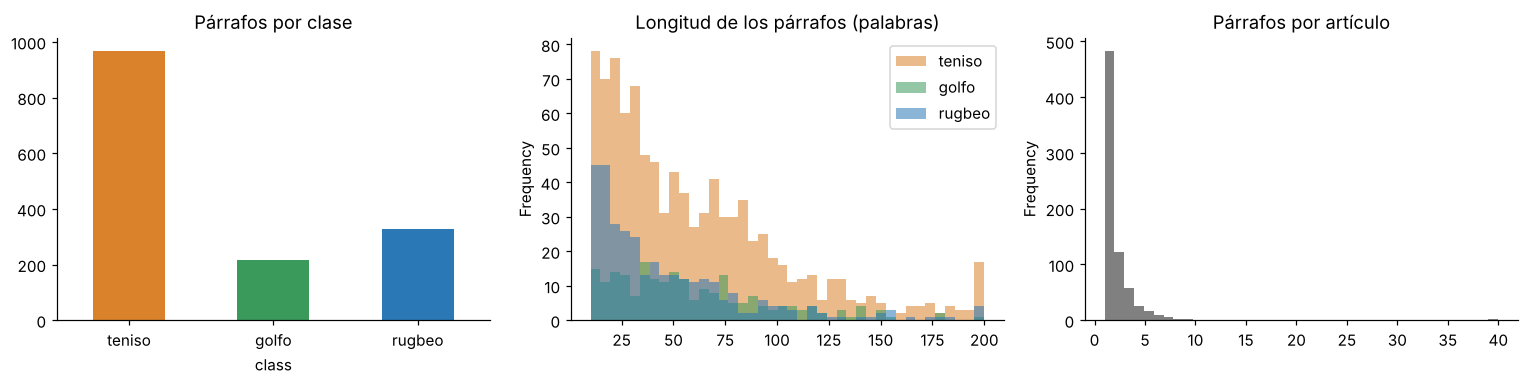

In [6]:
resumen = df.groupby("class").agg(
    parrafos=("text", "size"),
    articulos=("title", "nunique"),
    palabras_media=("text", lambda s: s.str.split().str.len().mean()),
).round(1).loc[list(TOPICS)]
display(resumen)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
resumen["parrafos"].plot.bar(ax=axes[0], color=[COLORES[c] for c in resumen.index], rot=0)
axes[0].set_title("Párrafos por clase")
for c in TOPICS:
    df.loc[df["class"] == c, "text"].str.split().str.len().clip(upper=200).plot.hist(
        ax=axes[1], bins=40, alpha=0.55, color=COLORES[c], label=c)
axes[1].set_title("Longitud de los párrafos (palabras)"); axes[1].legend()
df.groupby("title").size().clip(upper=40).plot.hist(ax=axes[2], bins=40, color="grey")
axes[2].set_title("Párrafos por artículo")
plt.tight_layout(); plt.show()

**Limitación de los datos.** El dataset está **desbalanceado**: hay unas
cuatro veces más tenis que golf. La Vikipedio en Esperanto tiene mucho más
contenido de tenis (cientos de biografías de tenistas) que de golf o rugby, y
el golf **no llega a los 300 párrafos recomendados**: se recogieron todos los
párrafos de golf que hay (la categoría tiene 17 artículos y el buscador apenas
añade un centenar más). Por eso se bajó el mínimo de palabras por párrafo a 10.

Cómo se compensa: no se re-muestrea (se perderían datos de tenis), sino que
**F1 macro** es la métrica principal (pesa igual las tres clases), Naive Bayes
usa probabilidades *a priori* uniformes (`fit_prior=False`) y los modelos
lineales usan `class_weight="balanced"`. La partición train/test se hace por
artículo.

In [7]:
for c in TOPICS:
    ejemplo = df[df["class"] == c].sample(1, random_state=SEED).iloc[0]
    print(f"[{c}] ({ejemplo['title']})\n  {ejemplo['text'][:300]}\n")

[teniso] (Tommy Haas)
  La dekstremana Haas estis ekde 1996 profesiulo kaj havis edukadon ĉe la tenisakademio de Nick Bolletieri. Tial Haas preskaŭ sian tutan vivon loĝis en Usono.

[golfo] (Margaret Abbott)
  Margaret Ives ABBOTT (la ‏ 15-an de junio 1878, en Kolkato, Brita Raĝo - la 10-an de junio 1955, Konektikuto, Usono) estis usona golfludanto. La unua virino se temas pri venki en olimpika ĉampioneco en golfo en la Somera Olimpiko 1900), same kiel la unua usona virino se temas pri venki en olimpika ĉ

[rugbeo] (Rugby)
  Rugby estas sur la orienta bordo de Warwickshire, proksime al la bordoj de Leicestershire kaj Northamptonshire. Ĝi estas je 134 km norde de Londono, je 48 km oriente de Birmingham kaj je 18 km oriente de Coventry.



### 1.5 Ruido de etiquetado (primera aproximación)

Los párrafos de los artículos de la categoría **heredan la etiqueta**, pero
muchos son genéricos: fechas, vida privada de un jugador, historia de un club...
(*"Ĝi estis fondita en 1950"*). Una medida sencilla del ruido: buscar párrafos
que **no contienen ningún término deportivo** de su deporte. Se define una lista
propia de raíces de cada deporte (sin usar el modelo, para no tener un
razonamiento circular). Los párrafos del buscador cumplen esto por construcción
(contienen la palabra clave), así que se mide solo sobre los de la categoría.
En la Fase 3 se mide el ruido de una segunda forma, con el propio clasificador.

In [8]:
RAICES_DOMINIO = {
    "teniso": ["tenis", "raked", "servo", "seto", "ATP", "WTA", "Grand Slam", "Wimbledon",
               "Roland", "Davis", "duobl", "unuopa", "turnir", "ludant", "matĉ"],
    "golfo": ["golf", "truo", "bastono", "PGA", "Masters", "Ryder", "ludant",
              "turnir", "ĉampion", "klub"],
    "rugbeo": ["rugbe", "ludant", "teamo", "matĉ", "provo", "pokal", "ŝlem", "ligo",
               "klub", "ĉampion", "Ses Nacioj", "turnir"],
}
patrones = {c: re.compile("|".join(map(re.escape, rs)), re.IGNORECASE) for c, rs in RAICES_DOMINIO.items()}
df["sin_termino_de_dominio"] = [not patrones[c].search(t) for t, c in zip(df["text"], df["class"])]

de_categoria = df[df["source"] == "kategorio"]
ruido_heuristico = de_categoria.groupby("class")["sin_termino_de_dominio"].mean().mul(100).round(1)
print("Párrafos de la categoría SIN ningún término de su deporte (%):")
print(ruido_heuristico.reindex(list(TOPICS)).to_string(),
      f"\nTotal: {de_categoria['sin_termino_de_dominio'].mean()*100:.1f} % "
      f"({de_categoria['sin_termino_de_dominio'].sum()} párrafos)")
print("\nEjemplos:")
for t in de_categoria[de_categoria["sin_termino_de_dominio"]].sample(4, random_state=SEED)["text"]:
    print(" ·", t[:160])

Párrafos de la categoría SIN ningún término de su deporte (%):
class
teniso    18.7
golfo     14.8
rugbeo    17.9 
Total: 18.1 % (146 párrafos)

Ejemplos:
 · Béla Kehrling maturiĝis en gimnazio en Budapeŝto. En la sensporta vivo li havis vendejon pri sportiloj. Lia edzino naskis 2 filojn.
 · En 2010 ŝi atingis la duonfinalojn de la Australian Open, perdis antaŭ Justine Henin.
 · En informstandoj pri Esperanto li rimarkis, ke la interesitojn speciale allogas bildstriaj albumoj en Esperanto, aparte la albumoj «La Nigra Insulo» kaj «La Kra
 · Ripozo kaj ĉeso de la respondecaj agadoj estas la plej grava parto de la kuracado.


## 2. Fase 2 – Modelo de NLP para Esperanto

Se implementa **desde cero** (sin spaCy, NLTK ni Stanza) un modelo basado en
reglas con un API como el de spaCy:

```python
nlp = load()
doc = nlp("La katoj manĝis fiŝon.")
for token in doc:
    token.text, token.lemma_, token.pos_, token.morph, token.is_stop
```

**¿Por qué funcionan las reglas?** El Esperanto marca la categoría gramatical
con la terminación, sin excepciones:

| Terminación | Categoría | Rasgos | Ejemplo → lema |
|---|---|---|---|
| `-o` (`-oj`, `-on`, `-ojn`) | sustantivo `NOUN` | número, caso | *pilkojn* → *pilko* |
| `-a` (`-aj`, `-an`, `-ajn`) | adjetivo `ADJ` | número, caso | *tenisajn* → *tenisa* |
| `-e` (`-en`) | adverbio `ADV` | dirección | *rapide* → *rapide* |
| `-as` / `-is` / `-os` | verbo `VERB` | presente / pasado / futuro | *trovis* → *trovi* |
| `-us` / `-u` / `-i` | verbo `VERB` | condicional / imperativo / infinitivo | *estu* → *esti* |
| `-ant- -int- -ont- -at- -it- -ot-` | participio | aspecto, voz | *skribita* → *skribi* |

Las palabras que no siguen estas reglas son de **clase cerrada** (artículo,
pronombres, la tabla de 45 correlativos, preposiciones, conjunciones,
numerales...) y se buscan en un **léxico** antes de aplicar las reglas.

**Pipeline** (`nlp.pipe_names`):

1. `normalizer`: Unicode NFC, apóstrofos y **sistema‑x** (`cx` → `ĉ`, `sx` → `ŝ`).
2. `tokenizer`: expresión regular (palabras con guion y elisión `l'`, números, URLs, signos).
3. `tagger`: UPOS + rasgos morfológicos (Universal Dependencies) por léxico y terminaciones.
   Mayúscula en mitad de oración → `PROPN`; letras `q w x y` → palabra extranjera.
4. `lemmatizer`: forma de diccionario y **descomposición en morfemas**
   (`malsanulejo` → `mal + san + ul + ej + o`) con prefijos/sufijos oficiales.
5. `stopwords`: `token.is_stop` a partir de una lista de **lemas** (así *estas,
   estis, estos* son todas stop-word por el lema *esti*).

También unifica variantes ortográficas con *ĥ* (*ĥemio* → *kemio*), muy
frecuentes en Vikipedio.

In [9]:
# ===== Código de eonlp/lexicon.py =====
"""Léxico cerrado del Esperanto.

El Esperanto tiene una gramática regular: casi todas las palabras "abiertas"
(sustantivos, adjetivos, verbos y adverbios derivados) se reconocen por su
terminación. Las excepciones son las palabras de clase cerrada (artículo,
pronombres, correlativos, preposiciones, conjunciones, numerales, adverbios
primarios...). Este módulo las enumera para que el etiquetador las reconozca
antes de aplicar las reglas de terminaciones.

Fuente: gramática básica del Esperanto (Fundamento de Esperanto, 16 reglas)
y la guía de la asignatura (nlp-esperantilo).
"""

# --------------------------------------------------------------------------
# Artículo
# --------------------------------------------------------------------------
ARTICLES = {"la", "l'"}

# --------------------------------------------------------------------------
# Pronombres personales (y sus formas en acusativo) y posesivos
# --------------------------------------------------------------------------
PERSONAL_PRONOUNS = ["mi", "vi", "li", "ŝi", "ĝi", "ni", "ili", "oni", "si", "ci"]

# --------------------------------------------------------------------------
# Correlativos: tabla de 5 prefijos x 9 sufijos
#   ki- (interrogativo), ti- (demostrativo), i- (indefinido),
#   ĉi- (universal), neni- (negativo)
# --------------------------------------------------------------------------
CORRELATIVE_PREFIXES = ["ki", "ti", "i", "ĉi", "neni"]
# sufijo -> (categoría UPOS, significado)
CORRELATIVE_SUFFIXES = {
    "u": ("DET", "individuo"),     # kiu, tiu, iu, ĉiu, neniu  (declinable: -j, -n)
    "o": ("PRON", "cosa"),         # kio, tio, io, ĉio, nenio   (declinable: -n)
    "a": ("DET", "cualidad"),      # kia, tia, ...              (declinable: -j, -n)
    "e": ("ADV", "lugar"),         # kie, tie, ...              (-n = dirección)
    "am": ("ADV", "tiempo"),       # kiam, tiam, ...
    "el": ("ADV", "modo"),         # kiel, tiel, ...
    "om": ("ADV", "cantidad"),     # kiom, tiom, ...
    "al": ("ADV", "causa"),        # kial, tial, ...
    "es": ("DET", "posesión"),     # kies, ties, ...
}

PREPOSITIONS = {
    "al", "anstataŭ", "antaŭ", "apud", "da", "de", "dum", "ekster", "el", "en",
    "ĝis", "inter", "je", "kontraŭ", "krom", "kun", "laŭ", "malgraŭ", "per",
    "po", "por", "post", "preter", "pri", "pro", "sen", "sub", "super", "sur",
    "tra", "trans", "ĉe", "ĉirkaŭ", "cis", "kontraŭe", "fare",
}

CONJUNCTIONS = {
    "kaj", "aŭ", "sed", "nek", "do", "ĉar", "ke", "se", "kvankam", "ĉu",
    "kvazaŭ", "dum", "ol", "tamen", "ju", "des", "nome", "plus", "minus",
}

# Adverbios primarios (no terminan en -e de forma regular)
PRIMARY_ADVERBS = {
    "ankaŭ", "ankoraŭ", "apenaŭ", "baldaŭ", "eĉ", "for", "hieraŭ", "hodiaŭ",
    "jam", "ja", "jen", "morgaŭ", "ne", "jes", "nun", "nur", "plu", "pli",
    "plej", "preskaŭ", "tre", "tro", "tuj", "ĉi", "almenaŭ", "adiaŭ", "mem",
    "ajn", "ambaŭ", "kvazaŭ", "malpli", "malplej", "ĉiam", "neniam", "iom",
    "tiel", "kiel", "ankoraŭfoje",
}

PARTICLES = {"ajn", "ĉi", "ja", "jen", "mem", "nur", "eĉ"}

INTERJECTIONS = {"ho", "ha", "ve", "nu", "fi", "hura", "aĥ", "ehe", "hej", "bis", "saluton", "dankon"}

# Abreviaturas frecuentes: ktp (kaj tiel plu = etc.), ekz (ekzemple), ks (kaj simile)...
ABBREVIATIONS = {"ktp", "ekz", "ks", "kp", "vd", "ĉ", "pp", "ktr", "resp", "bv", "sk"}

# Numerales cardinales básicos
NUMERAL_UNITS = ["unu", "du", "tri", "kvar", "kvin", "ses", "sep", "ok", "naŭ"]
NUMERAL_WORDS = set(NUMERAL_UNITS) | {"nul", "dek", "cent", "mil"}

# Verbos auxiliares / muy frecuentes que se tratan como stop-words por lema
AUXILIARY_VERBS = {"esti", "havi", "povi", "devi", "voli", "fari", "iĝi", "igi", "ŝajni"}


def correlatives():
    """Genera la tabla completa de correlativos con sus formas declinadas.

    Devuelve un diccionario ``forma -> (upos, lema, rasgos)``.
    """
    table = {}
    for pre in CORRELATIVE_PREFIXES:
        for suf, (upos, _meaning) in CORRELATIVE_SUFFIXES.items():
            base = pre + suf
            table[base] = (upos, base, {"PronType": _pron_type(pre)})
            if suf in ("u", "a"):
                table[base + "j"] = (upos, base, {"PronType": _pron_type(pre), "Number": "Plur"})
                table[base + "n"] = (upos, base, {"PronType": _pron_type(pre), "Case": "Acc"})
                table[base + "jn"] = (upos, base, {"PronType": _pron_type(pre), "Number": "Plur", "Case": "Acc"})
            elif suf == "o":
                table[base + "n"] = (upos, base, {"PronType": _pron_type(pre), "Case": "Acc"})
            elif suf == "e":
                table[base + "n"] = (upos, base, {"PronType": _pron_type(pre), "Case": "Acc"})
    return table


def _pron_type(prefix):
    return {"ki": "Int", "ti": "Dem", "i": "Ind", "ĉi": "Tot", "neni": "Neg"}[prefix]


def pronouns():
    """Pronombres personales, posesivos y sus formas declinadas.

    Devuelve un diccionario ``forma -> (upos, lema, rasgos)``.
    """
    table = {}
    for p in PERSONAL_PRONOUNS:
        table[p] = ("PRON", p, {"PronType": "Prs"})
        table[p + "n"] = ("PRON", p, {"PronType": "Prs", "Case": "Acc"})
        poss = p + "a"  # mia, via, lia, ŝia, ĝia, nia, ilia, onia, sia
        table[poss] = ("DET", poss, {"Poss": "Yes"})
        table[poss + "j"] = ("DET", poss, {"Poss": "Yes", "Number": "Plur"})
        table[poss + "n"] = ("DET", poss, {"Poss": "Yes", "Case": "Acc"})
        table[poss + "jn"] = ("DET", poss, {"Poss": "Yes", "Number": "Plur", "Case": "Acc"})
    return table


def closed_class_lexicon():
    """Construye el léxico completo de palabras de clase cerrada.

    El orden importa: las entradas posteriores sobrescriben a las anteriores
    (p. ej. ``ĉi`` es a la vez prefijo correlativo y partícula).
    Devuelve ``forma -> (upos, lema, rasgos)``.
    """
    lex = {}
    for w in NUMERAL_WORDS:
        lex[w] = ("NUM", w, {"NumType": "Card"})
    for w in INTERJECTIONS:
        lex[w] = ("INTJ", w, {})
    for w in PRIMARY_ADVERBS:
        lex[w] = ("ADV", w, {})
    for w in ABBREVIATIONS:
        lex[w] = ("X", w, {"Abbr": "Yes"})
    for w in CONJUNCTIONS:
        upos = "SCONJ" if w in {"ke", "se", "ĉar", "kvankam", "ĉu", "kvazaŭ", "dum", "ol"} else "CCONJ"
        lex[w] = (upos, w, {})
    for w in PREPOSITIONS:
        lex[w] = ("ADP", w, {})
    lex.update(correlatives())
    lex.update(pronouns())
    for w in PARTICLES:
        lex[w] = ("PART", w, {})
    for w in ARTICLES:
        lex[w] = ("DET", "la", {"Definite": "Def", "PronType": "Art"})
    # "dum" es preposición y conjunción; dejamos ADP como más frecuente.
    lex["dum"] = ("ADP", "dum", {})
    return lex


# --------------------------------------------------------------------------
# Stop-words
# --------------------------------------------------------------------------
def default_stop_words():
    """Lista de stop-words: todas las palabras de clase cerrada + verbos auxiliares.

    Se guarda como conjunto de **lemas**, de forma que cualquier forma
    flexionada (``estas``, ``estis``, ``tiujn``...) se considera stop-word.
    """
    stops = {lemma for (_upos, lemma, _f) in closed_class_lexicon().values()}
    stops |= set(closed_class_lexicon())
    stops |= AUXILIARY_VERBS
    # palabras muy frecuentes sin carga temática en textos enciclopédicos
    stops |= {
        "multa", "multe", "pli", "alia", "sama", "nova", "unua", "dua", "tria",
        "granda", "malgranda", "bona", "nomi", "uzi", "ekzisti", "trovi",
        "jaro", "parto", "ekzemplo", "ekzemple", "speco", "tipo", "kelka",
        "diversa", "simila", "grava", "ofte", "kutime", "ĝenerale", "nomo",
    }
    return stops

In [10]:
# ===== Código de eonlp/nlp.py =====
"""Modelo de NLP para Esperanto basado en reglas, con un API similar a spaCy.

Uso::

    nlp = load()
    doc = nlp("La katoj manĝis fiŝon.")
    for token in doc:
        print(token.text, token.lemma_, token.pos_, token.morph, token.is_stop)

Componentes del pipeline (``nlp.pipe_names``):

1. ``normalizer``  - normaliza Unicode y el sistema-x (``cx`` -> ``ĉ``).
2. ``tokenizer``   - divide el texto en tokens con expresiones regulares.
3. ``tagger``      - etiquetado gramatical (UPOS) y morfológico por terminaciones.
4. ``lemmatizer``  - forma de diccionario (``-o``, ``-a``, ``-i``, ``-e``).
5. ``stopwords``   - marca ``token.is_stop`` a partir de una lista de lemas.

Todo está implementado desde cero, sin librerías de NLP: el Esperanto es
regular y sin excepciones, así que unas pocas reglas cubren la mayoría de casos.
"""

import re
import unicodedata


# --------------------------------------------------------------------------
# Normalización
# --------------------------------------------------------------------------
# Sistema-x: forma habitual de escribir Esperanto sin teclado especial.
X_SYSTEM = {
    "cx": "ĉ", "gx": "ĝ", "hx": "ĥ", "jx": "ĵ", "sx": "ŝ", "ux": "ŭ",
    "Cx": "Ĉ", "Gx": "Ĝ", "Hx": "Ĥ", "Jx": "Ĵ", "Sx": "Ŝ", "Ux": "Ŭ",
    "CX": "Ĉ", "GX": "Ĝ", "HX": "Ĥ", "JX": "Ĵ", "SX": "Ŝ", "UX": "Ŭ",
}
_X_RE = re.compile("|".join(X_SYSTEM))


# Variantes ortográficas con "ĥ" que hoy se escriben con "k"
# (ĥemio -> kemio, teĥniko -> tekniko...). Se unifican para que el modelo
# vea una sola forma de cada raíz.
H_VARIANTS = {"ĥem": "kem", "ĥlor": "klor", "ĥrom": "krom", "ĥaos": "kaos",
              "teĥn": "tekn", "meĥan": "mekan", "arĥe": "arke", "ĥiral": "kiral",
              "ĥoler": "koler", "ĥirurg": "kirurg"}
_H_RE = re.compile("|".join(H_VARIANTS), re.IGNORECASE)


def unify_spelling(word):
    """Unifica variantes ortográficas: ``bioĥemia`` -> ``biokemia``."""
    if "ĥ" not in word.lower():
        return word
    return _H_RE.sub(lambda m: H_VARIANTS[m.group(0).lower()], word)


def normalize_text(text, x_system=True):
    """Normaliza a NFC (letras con diacrítico en un solo carácter) y,
    opcionalmente, convierte el sistema-x a letras con diacrítico."""
    text = unicodedata.normalize("NFC", text)
    # comillas y apóstrofos tipográficos -> ASCII
    text = text.replace("’", "'").replace("‘", "'").replace("´", "'")
    if x_system:
        text = _X_RE.sub(lambda m: X_SYSTEM[m.group(0)], text)
    return text


# --------------------------------------------------------------------------
# Tokenizador
# --------------------------------------------------------------------------
ESPERANTO_LETTERS = "a-zA-ZĉĝĥĵŝŭĈĜĤĴŜŬ"
_TOKEN_RE = re.compile(
    rf"""
    (?P<url>https?://\S+)                                   # URLs
  | (?P<num>\d+(?:[.,]\d+)*)                                # números: 1 000, 3,14
  | (?P<word>[\w]+(?:[-'][\w]+)*'?)                         # palabras (incl. guion y elisión l')
  | (?P<punct>[^\w\s])                                      # signos de puntuación
    """,
    re.VERBOSE | re.UNICODE,
)


def tokenize(text):
    """Devuelve una lista de tuplas ``(texto, posición, espacio_posterior)``."""
    out = []
    for m in _TOKEN_RE.finditer(text):
        start, end = m.span()
        ws = text[end:end + 1] if end < len(text) and text[end].isspace() else ""
        out.append((m.group(0), start, ws))
    return out


# --------------------------------------------------------------------------
# Objetos Token y Doc (API tipo spaCy)
# --------------------------------------------------------------------------
class MorphAnalysis(dict):
    """Rasgos morfológicos (``Number=Plur|Case=Acc``) al estilo Universal Dependencies."""

    def __str__(self):
        return "|".join(f"{k}={v}" for k, v in sorted(self.items()))

    def get(self, key, default=None):  # noqa: D401 - igual que dict.get
        return super().get(key, default)


class Token:
    """Un token del documento.

    Atributos principales (mismos nombres que spaCy):
    ``text``, ``i``, ``idx``, ``whitespace_``, ``lemma_``, ``pos_``, ``tag_``,
    ``morph``, ``is_stop``, ``is_punct``, ``is_alpha``, ``like_num``, ``like_url``.
    Extra propio: ``root_`` (raíz sin terminación gramatical) y ``morphemes``.
    """

    __slots__ = ("doc", "text", "i", "idx", "whitespace_", "lemma_", "pos_",
                 "tag_", "morph", "is_stop", "root_", "morphemes")

    def __init__(self, doc, text, i, idx, whitespace=""):
        self.doc = doc
        self.text = text
        self.i = i
        self.idx = idx
        self.whitespace_ = whitespace
        self.lemma_ = text.lower()
        self.pos_ = "X"
        self.tag_ = ""
        self.morph = MorphAnalysis()
        self.is_stop = False
        self.root_ = text.lower()
        self.morphemes = [text.lower()]

    # propiedades derivadas -------------------------------------------------
    @property
    def lower_(self):
        return self.text.lower()

    @property
    def text_with_ws(self):
        return self.text + self.whitespace_

    @property
    def is_punct(self):
        return self.pos_ == "PUNCT"

    @property
    def is_alpha(self):
        return self.text.replace("'", "").isalpha()

    @property
    def is_digit(self):
        return self.text.isdigit()

    @property
    def like_num(self):
        return self.pos_ == "NUM"

    @property
    def like_url(self):
        return self.text.startswith(("http://", "https://"))

    @property
    def is_sent_start(self):
        return self.i == 0 or self.doc[self.i - 1].text in {".", "!", "?"}

    def __len__(self):
        return len(self.text)

    def __str__(self):
        return self.text

    def __repr__(self):
        return self.text


class Span:
    """Secuencia contigua de tokens (se usa para las oraciones)."""

    def __init__(self, doc, start, end):
        self.doc, self.start, self.end = doc, start, end

    def __iter__(self):
        return iter(self.doc.tokens[self.start:self.end])

    def __len__(self):
        return self.end - self.start

    def __getitem__(self, i):
        return self.doc.tokens[self.start:self.end][i]

    @property
    def text(self):
        return "".join(t.text_with_ws for t in self).strip()

    def __repr__(self):
        return self.text


class Doc:
    """Documento procesado: contenedor de ``Token`` en orden."""

    def __init__(self, text, words=None):
        self.text = text
        self.tokens = []
        for i, (w, idx, ws) in enumerate(words or []):
            self.tokens.append(Token(self, w, i, idx, ws))

    def __iter__(self):
        return iter(self.tokens)

    def __len__(self):
        return len(self.tokens)

    def __getitem__(self, i):
        if isinstance(i, slice):
            start, stop, _ = i.indices(len(self))
            return Span(self, start, stop)
        return self.tokens[i]

    @property
    def sents(self):
        """Segmentación en oraciones por signos de puntuación final."""
        start = 0
        for t in self.tokens:
            if t.text in {".", "!", "?"}:
                yield Span(self, start, t.i + 1)
                start = t.i + 1
        if start < len(self.tokens):
            yield Span(self, start, len(self.tokens))

    def to_table(self):
        """Lista de diccionarios (cómodo para crear un ``pandas.DataFrame``)."""
        return [
            {"text": t.text, "lemma": t.lemma_, "pos": t.pos_, "tag": t.tag_,
             "morph": str(t.morph), "root": t.root_, "is_stop": t.is_stop}
            for t in self.tokens
        ]

    def __repr__(self):
        return self.text


# --------------------------------------------------------------------------
# Análisis morfológico por terminaciones
# --------------------------------------------------------------------------
# Terminaciones verbales: tiempo/modo
VERB_ENDINGS = {
    "as": {"Tense": "Pres", "Mood": "Ind", "VerbForm": "Fin"},
    "is": {"Tense": "Past", "Mood": "Ind", "VerbForm": "Fin"},
    "os": {"Tense": "Fut", "Mood": "Ind", "VerbForm": "Fin"},
    "us": {"Mood": "Cnd", "VerbForm": "Fin"},
    "u": {"Mood": "Imp", "VerbForm": "Fin"},
    "i": {"VerbForm": "Inf"},
}

# Sufijos de participio: (aspecto, tiempo, voz)
PARTICIPLES = {
    "ant": ("Imp", "Pres", "Act"), "int": ("Perf", "Past", "Act"), "ont": ("Prosp", "Fut", "Act"),
    "at": ("Imp", "Pres", "Pass"), "it": ("Perf", "Past", "Pass"), "ot": ("Prosp", "Fut", "Pass"),
}
# Palabras que parecen participios pero no lo son (raíz lexicalizada)
PARTICIPLE_EXCEPTIONS = {
    "konstanta", "konstante", "elefanta", "kvanta", "privata", "delikata", "akurata",
    "adekvata", "infinita", "eksplicita", "implicita", "favorita", "granda",
    "kandidata", "senata", "pirata", "kvalita", "klimata", "simpatia", "planta",
    "giganta", "elegante", "eleganta", "brilanta", "variante", "konsonanta",
    "elita", "spirita", "merita", "subita", "subite", "limita", "unuopa", "dekstra",
    "kalkulita", "sankta", "akcidenta", "frekventa", "inteligenta", "potenca",
    "kompetenta", "evidenta", "evidente", "permanenta", "permanente", "absoluta",
    "absolute", "pacienta", "studenta", "doktoranta", "abunda",
}
MIN_STEM = 2  # longitud mínima de raíz para aceptar una terminación

# Afijos (para descomponer en morfemas: mal-san-ul-ej-o)
PREFIXES = ["mal", "re", "ek", "dis", "ge", "eks", "bo", "fi", "mis", "pra", "for", "ne"]
SUFFIXES = ["ad", "aĉ", "aĵ", "an", "ar", "ec", "eg", "ej", "em", "end", "er", "estr",
            "et", "id", "ig", "iĝ", "il", "in", "ind", "ing", "ism", "ist", "obl", "on",
            "op", "uj", "ul", "um"]

_NUM_RE = re.compile(
    r"^(?:(?:" + "|".join(NUMERAL_UNITS) + r")?(?:dek|cent|mil))+(?:" + "|".join(NUMERAL_UNITS) + r")?$"
)
_FOREIGN_RE = re.compile(r"[qwxyQWXY]")


def split_morphemes(stem, min_root=3):
    """Descompone (de forma voraz) una raíz en prefijos + raíz + sufijos.

    ``malsanulejo`` -> raíz ``malsanulej`` -> ``['mal', 'san', 'ul', 'ej']``.
    Solo se separa un afijo si la raíz restante conserva ``min_root`` letras,
    para no destrozar raíces cortas (``ideo`` no es ``id-eo``).
    """
    prefixes, suffixes = [], []
    changed = True
    while changed:
        changed = False
        for p in PREFIXES:
            if stem.startswith(p) and len(stem) - len(p) >= min_root + 1:
                prefixes.append(p)
                stem = stem[len(p):]
                changed = True
                break
    changed = True
    while changed:
        changed = False
        for s in sorted(SUFFIXES, key=len, reverse=True):
            if stem.endswith(s) and len(stem) - len(s) >= min_root:
                suffixes.insert(0, s)
                stem = stem[: -len(s)]
                changed = True
                break
    return prefixes + [stem] + suffixes


class EsperantoAnalyzer:
    """Etiquetador + lematizador basado en reglas.

    Devuelve, para una palabra, ``(upos, lemma, rasgos, raíz)``.
    """

    def __init__(self):
        self.lexicon = closed_class_lexicon()

    def analyze(self, word, sent_start=False):
        low = unify_spelling(word.lower())

        # 1. Puntuación y números ------------------------------------------
        if not any(ch.isalnum() for ch in word):
            return "PUNCT", word, {}, word
        if word.replace(".", "").replace(",", "").isdigit():
            return "NUM", word, {"NumType": "Card"}, word
        if word.startswith(("http://", "https://")):
            return "X", word, {}, word

        # 2. Léxico cerrado -------------------------------------------------
        if low in self.lexicon:
            upos, lemma, feats = self.lexicon[low]
            return upos, lemma, dict(feats), lemma
        if _NUM_RE.match(low):
            return "NUM", low, {"NumType": "Card"}, low

        # 3. Elisión poética: "kor'" = "koro"
        if low.endswith("'") and len(low) > 2:
            return "NOUN", low[:-1] + "o", {"Number": "Sing", "Case": "Nom"}, low[:-1]

        # 4. Nombres propios y palabras extranjeras ------------------------
        is_capital = word[:1].isupper()
        if _FOREIGN_RE.search(low) or any(ch.isdigit() for ch in low):
            return ("PROPN" if is_capital else "X"), word, {"Foreign": "Yes"}, low
        if is_capital and not sent_start and not self._has_eo_ending(low):
            return "PROPN", word, {}, low

        # 5. Reglas de terminación (núcleo del modelo) ---------------------
        res = self._by_ending(low)
        if res is not None:
            upos, lemma, feats, root = res
            if is_capital and not sent_start:
                # En mitad de la oración, la mayúscula indica nombre propio
                # ("Eŭropo", "Parizo", "Marie Curie"). Los adjetivos de
                # nacionalidad se escriben en minúscula en Esperanto.
                upos = "PROPN"
                lemma = word[:1] + lemma[1:] if res[0] == "NOUN" else word
            return upos, lemma, feats, root

        return ("PROPN" if is_capital else "X"), word if is_capital else low, {}, low

    # ------------------------------------------------------------------
    @staticmethod
    def _has_eo_ending(low):
        return bool(re.search(r"(o|oj|on|ojn|a|aj|an|ajn|e|en|as|is|os|us|u|i)$", low))

    def _by_ending(self, low):
        # Sustantivos: -o(j)(n)
        m = re.match(r"^(.+?)o(j?)(n?)$", low)
        if m and len(m.group(1)) >= MIN_STEM:
            stem = m.group(1)
            feats = {"Number": "Plur" if m.group(2) else "Sing", "Case": "Acc" if m.group(3) else "Nom"}
            return "NOUN", stem + "o", feats, stem

        # Adjetivos: -a(j)(n)  (pueden ser participios: -ant-a, -it-a...)
        m = re.match(r"^(.+?)a(j?)(n?)$", low)
        if m and len(m.group(1)) >= MIN_STEM:
            stem = m.group(1)
            feats = {"Number": "Plur" if m.group(2) else "Sing", "Case": "Acc" if m.group(3) else "Nom"}
            part = self._participle(stem, low)
            if part:
                verb_stem, pfeats = part
                feats.update(pfeats)
                return "ADJ", verb_stem + "i", feats, verb_stem
            if stem in NUMERAL_UNITS or stem in {"dek", "cent", "mil"} or _NUM_RE.match(stem):
                feats["NumType"] = "Ord"     # dua, tria, dudeka...
            return "ADJ", stem + "a", feats, stem

        # Adverbios derivados: -e(n)
        m = re.match(r"^(.+?)e(n?)$", low)
        if m and len(m.group(1)) >= MIN_STEM:
            stem = m.group(1)
            feats = {"Case": "Acc"} if m.group(2) else {}   # -en = dirección (hejmen)
            part = self._participle(stem, low)
            if part:
                verb_stem, pfeats = part
                feats.update(pfeats)
                return "ADV", verb_stem + "i", feats, verb_stem
            return "ADV", stem + "e", feats, stem

        # Verbos: -as, -is, -os, -us, -u, -i
        for ending in ("as", "is", "os", "us", "u", "i"):
            if low.endswith(ending) and len(low) - len(ending) >= MIN_STEM:
                stem = low[: -len(ending)]
                return "VERB", stem + "i", dict(VERB_ENDINGS[ending]), stem
        return None

    @staticmethod
    def _participle(stem, word):
        """Si ``stem`` termina en un sufijo de participio, devuelve la raíz verbal."""
        if word in PARTICIPLE_EXCEPTIONS:
            return None
        for suf, (aspect, tense, voice) in PARTICIPLES.items():
            if stem.endswith(suf) and len(stem) - len(suf) >= 3:
                return stem[: -len(suf)], {"VerbForm": "Part", "Aspect": aspect,
                                            "Tense": tense, "Voice": voice}
        return None


# --------------------------------------------------------------------------
# Pipeline estilo spaCy
# --------------------------------------------------------------------------
class Esperanto:
    """Objeto ``nlp``: aplica el pipeline completo a un texto y devuelve un ``Doc``."""

    lang = "eo"

    def __init__(self, stop_words=None, x_system=True):
        self.x_system = x_system
        self.analyzer = EsperantoAnalyzer()
        self.stop_words = set(stop_words) if stop_words is not None else default_stop_words()
        self.pipeline = [
            ("tagger", self._tagger),
            ("lemmatizer", self._lemmatizer),
            ("stopwords", self._stopwords),
        ]

    @property
    def pipe_names(self):
        return ["normalizer", "tokenizer"] + [name for name, _ in self.pipeline]

    # API pública ---------------------------------------------------------
    def make_doc(self, text):
        """Normaliza y tokeniza (sin el resto del pipeline)."""
        text = normalize_text(text, self.x_system)
        return Doc(text, tokenize(text))

    def __call__(self, text):
        doc = self.make_doc(text)
        for _name, component in self.pipeline:
            doc = component(doc)
        return doc

    def pipe(self, texts):
        """Procesa un iterable de textos (generador, como ``spacy.Language.pipe``)."""
        for text in texts:
            yield self(text)

    def add_stop_words(self, words):
        self.stop_words |= {w.lower() for w in words}

    # Componentes ---------------------------------------------------------
    def _tagger(self, doc):
        for tok in doc:
            upos, lemma, feats, root = self.analyzer.analyze(tok.text, tok.is_sent_start)
            tok.pos_ = upos
            tok.morph = MorphAnalysis(feats)
            tok.tag_ = upos + ("__" + str(tok.morph) if feats else "")
            tok.lemma_ = lemma   # se guarda aquí y lo confirma el lematizador
            tok.root_ = root
        return doc

    def _lemmatizer(self, doc):
        for tok in doc:
            if tok.pos_ in {"NOUN", "ADJ", "VERB", "ADV"}:
                tok.lemma_ = tok.lemma_.lower()
                tok.morphemes = split_morphemes(tok.root_)
            elif tok.pos_ == "PROPN":
                tok.morphemes = [tok.root_]
            else:
                tok.morphemes = [tok.lemma_.lower()]
        return doc

    def _stopwords(self, doc):
        for tok in doc:
            tok.is_stop = tok.lower_ in self.stop_words or tok.lemma_.lower() in self.stop_words
        return doc

    def __repr__(self):
        return f"<Esperanto nlp pipeline={self.pipe_names}>"


def load(**kwargs):
    """Equivalente a ``spacy.load(...)``: devuelve el pipeline listo para usar."""
    return Esperanto(**kwargs)

### 2.1 Demostración del API

In [11]:
nlp = load()
print(nlp)
doc = nlp("La junaj sciencistoj malkovris novajn elementojn en la laboratorio de Marie Curie, "
          "kaj ili skribos artikolon pri la radioaktiveco.")
pd.DataFrame(doc.to_table())

<Esperanto nlp pipeline=['normalizer', 'tokenizer', 'tagger', 'lemmatizer', 'stopwords']>


,text,lemma,pos,tag,morph,root,is_stop
0,La,la,DET,DET__Definite=Def|PronType=Art,Definite=Def|PronType=Art,la,True
1,junaj,juna,ADJ,ADJ__Case=Nom|Number=Plur,Case=Nom|Number=Plur,jun,False
2,sciencistoj,sciencisto,NOUN,NOUN__Case=Nom|Number=Plur,Case=Nom|Number=Plur,sciencist,False
3,malkovris,malkovri,VERB,VERB__Mood=Ind|Tense=Past|VerbForm=Fin,Mood=Ind|Tense=Past|VerbForm=Fin,malkovr,False
4,novajn,nova,ADJ,ADJ__Case=Acc|Number=Plur,Case=Acc|Number=Plur,nov,True
5,elementojn,elemento,NOUN,NOUN__Case=Acc|Number=Plur,Case=Acc|Number=Plur,element,False
6,en,en,ADP,ADP,,en,True
7,la,la,DET,DET__Definite=Def|PronType=Art,Definite=Def|PronType=Art,la,True
8,laboratorio,laboratorio,NOUN,NOUN__Case=Nom|Number=Sing,Case=Nom|Number=Sing,laboratori,False
9,de,de,ADP,ADP,,de,True


In [12]:
# Oraciones, morfemas, sistema-x y stop-words
doc = nlp("Mi sxatas la malsanulejon. Cxu vi vidis la ĉielarkon hieraŭ?")
print("Oraciones:", [s.text for s in doc.sents])
print("Normalizado (sistema-x):", doc.text)
for palabra in ["malsanulejo", "ĉielarko", "lernejestro", "maljuneco", "fotosintezo"]:
    print(f"  {palabra:<12} → morfemas {nlp(palabra)[0].morphemes}")
print("Stop-words en el texto:", [t.text for t in doc if t.is_stop])
print("Tamaño de la lista de stop-words:", len(nlp.stop_words))

Oraciones: ['Mi ŝatas la malsanulejon.', 'Ĉu vi vidis la ĉielarkon hieraŭ?']
Normalizado (sistema-x): Mi ŝatas la malsanulejon. Ĉu vi vidis la ĉielarkon hieraŭ?
  malsanulejo  → morfemas ['mal', 'san', 'ul', 'ej']
  ĉielarko     → morfemas ['ĉielark']
  lernejestro  → morfemas ['lern', 'ej', 'estr']
  maljuneco    → morfemas ['mal', 'jun', 'ec']
  fotosintezo  → morfemas ['fotosintez']
Stop-words en el texto: ['Mi', 'la', 'Ĉu', 'vi', 'la', 'hieraŭ']
Tamaño de la lista de stop-words: 307


### 2.2 Evaluación del modelo sobre un pequeño *gold standard*

Para comprobar que el etiquetador funciona se anotan a mano unas frases
(etiqueta UPOS y lema esperados) y se mide la exactitud.

In [13]:
GOLD = [
    ("La katoj manĝis fiŝon .", "DET NOUN VERB NOUN PUNCT", "la kato manĝi fiŝo ."),
    ("Mi ŝatas legi interesajn librojn .", "PRON VERB VERB ADJ NOUN PUNCT", "mi ŝati legi interesa libro ."),
    ("Kiuj sciencistoj malkovris la elektronon ?", "DET NOUN VERB DET NOUN PUNCT", "kiu sciencisto malkovri la elektrono ?"),
    ("La akvo bolas je cent gradoj .", "DET NOUN VERB ADP NUM NOUN PUNCT", "la akvo boli je cent grado ."),
    ("Ŝi iras hejmen rapide ĉar pluvas .", "PRON VERB ADV ADV SCONJ VERB PUNCT", "ŝi iri hejme rapide ĉar pluvi ."),
    ("Ĉiuj vivaj ĉeloj enhavas DNA kaj proteinojn .", "DET ADJ NOUN VERB PROPN CCONJ NOUN PUNCT", "ĉiu viva ĉelo enhavi DNA kaj proteino ."),
    ("La skribita letero estis sendita al Parizo .", "DET ADJ NOUN VERB ADJ ADP PROPN PUNCT", "la skribi letero esti sendi al Parizo ."),
    ("Se vi volus , ni povus helpi vin .", "SCONJ PRON VERB PUNCT PRON VERB VERB PRON PUNCT", "se vi voli , ni povi helpi vi ."),
    ("Tiu ĉi reakcio produktas varmon kaj lumon .", "DET PART NOUN VERB NOUN CCONJ NOUN PUNCT", "tiu ĉi reakcio produkti varmo kaj lumo ."),
    ("La dua leĝo de Newton priskribas la forton .", "DET ADJ NOUN ADP PROPN VERB DET NOUN PUNCT", "la dua leĝo de Newton priskribi la forto ."),
]
aciertos_pos = aciertos_lema = total = 0
errores = []
for frase, pos, lemas in GOLD:
    doc = nlp(frase)
    for tok, p, l in zip(doc, pos.split(), lemas.split()):
        total += 1
        aciertos_pos += tok.pos_ == p
        aciertos_lema += tok.lemma_ == l
        if tok.pos_ != p or tok.lemma_ != l:
            errores.append((tok.text, tok.pos_, p, tok.lemma_, l))
print(f"Exactitud POS:   {aciertos_pos/total:.1%}  ({total} tokens)")
print(f"Exactitud lemas: {aciertos_lema/total:.1%}")
if errores:
    display(pd.DataFrame(errores, columns=["token", "pos_pred", "pos_gold", "lema_pred", "lema_gold"]))

Exactitud POS:   100.0%  (73 tokens)
Exactitud lemas: 100.0%


### 2.3 El modelo sobre el corpus

Distribución de categorías gramaticales en el dataset y palabras que el modelo
no sabe clasificar (`X`). Esto sirve para detectar casos que las reglas no
cubren (palabras extranjeras, fórmulas químicas, abreviaturas).

1512 párrafos procesados en 0.7 s (102,098 tokens)


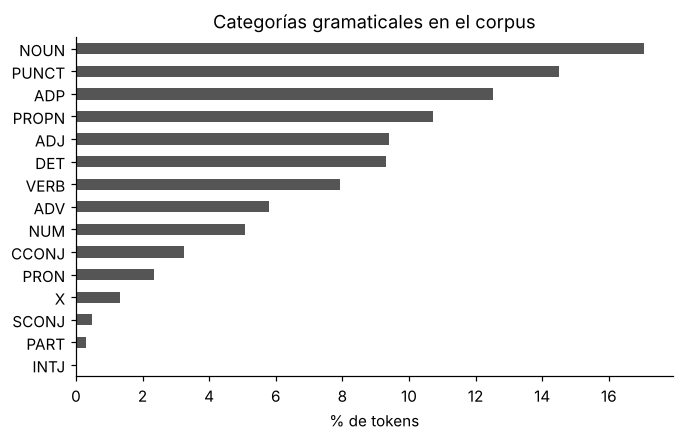

Palabras más frecuentes etiquetadas como X: ['an', 'a', 'aj', 'of', 'n', 'm', 'ktp', 'km', 'and', 'von', 'i', 'cm', 'rugby', 't', 'ekz']


In [14]:
t0 = time.time()
docs = list(nlp.pipe(df["text"]))
print(f"{len(docs)} párrafos procesados en {time.time() - t0:.1f} s "
      f"({sum(len(d) for d in docs):,} tokens)")

conteo_pos = pd.Series([t.pos_ for d in docs for t in d]).value_counts()
ax = (conteo_pos / conteo_pos.sum() * 100).plot.barh(figsize=(7, 4), color="#555")
ax.invert_yaxis(); ax.set_xlabel("% de tokens"); ax.set_title("Categorías gramaticales en el corpus")
plt.show()
desconocidas = pd.Series([t.text for d in docs for t in d if t.pos_ == "X"]).value_counts()
print("Palabras más frecuentes etiquetadas como X:", list(desconocidas.head(15).index))

## 3. Fase 3 – Clasificación

### 3.1 Representación tabular (vectorización)

Cada párrafo se convierte, con el modelo de la Fase 2, en la lista de
**lemas de las palabras con contenido** (sustantivos, nombres propios,
adjetivos, verbos y adverbios), sin stop-words, números ni signos. Después se
aplica **TF-IDF** (`sublinear_tf`, `min_df=2`, `max_df=0.9`).

Se comparan tres representaciones para justificar el uso del modelo de NLP:

* `text`: palabra en minúsculas, **sin lematizar** (línea base);
* `lemma`: **lema** (`pilkojn`, `pilko` → `pilko`);
* `root`: **raíz** sin terminación (`tenisa`, `teniso` → `tenis`).

In [15]:
# ===== Código de eonlp/classify.py =====
"""Fase 3 - Vectorización, clasificación y clasificación de páginas web.

* ``preprocess``: usa el modelo de NLP propio para convertir cada párrafo en
  una secuencia de lemas (o raíces) de palabras con contenido.
* ``build_pipeline``: TF-IDF + clasificador lineal de scikit-learn.
* ``fetch_web_paragraphs``: *web scraping* con ``requests`` + ``BeautifulSoup``.
* ``classify_paragraphs``: probabilidad de cada categoría para un texto web.
"""

import re

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC


CONTENT_POS = {"NOUN", "PROPN", "ADJ", "VERB", "ADV"}
SEED = 42


# --------------------------------------------------------------------------
# Preprocesamiento con el modelo de NLP propio
# --------------------------------------------------------------------------
def doc_to_features(doc, mode="lemma", min_len=3):
    """Extrae las "palabras" que representan un documento.

    ``mode``:
      * ``"lemma"``  - lema (``fizikaj`` -> ``fizika``; ``atomoj`` -> ``atomo``)
      * ``"root"``   - raíz sin terminación (``fizika``/``fiziko`` -> ``fizik``),
        aprovecha la morfología aglutinante del Esperanto.
      * ``"text"``   - palabra en minúsculas sin lematizar (línea base).
    Se descartan stop-words, signos de puntuación, números y palabras cortas.
    """
    feats = []
    for t in doc:
        if t.is_stop or t.pos_ not in CONTENT_POS or not t.is_alpha:
            continue
        value = {"lemma": t.lemma_, "root": t.root_, "text": t.lower_}[mode].lower()
        if len(value) >= min_len:
            feats.append(value)
    return feats


def preprocess(texts, nlp, mode="lemma"):
    """Devuelve una lista de cadenas de *features* separadas por espacios."""
    return [" ".join(doc_to_features(doc, mode)) for doc in nlp.pipe(texts)]


def preprocess_all_modes(texts, nlp, modes=("text", "lemma", "root")):
    """Igual que ``preprocess`` pero obtiene varias representaciones con una
    sola pasada del modelo de NLP (ahorra tiempo de ejecución)."""
    out = {m: [] for m in modes}
    for doc in nlp.pipe(texts):
        for m in modes:
            out[m].append(" ".join(doc_to_features(doc, m)))
    return out


def make_vectorizer(ngram_range=(1, 1), min_df=2, max_df=0.9):
    """TF-IDF sobre los lemas ya preprocesados (separados por espacios)."""
    return TfidfVectorizer(
        token_pattern=r"\S+", lowercase=False, ngram_range=ngram_range,
        min_df=min_df, max_df=max_df, sublinear_tf=True,
    )


def candidate_models():
    """Clasificadores ligeros (entrenan en segundos sin GPU)."""
    return {
        # El dataset está desbalanceado (mucho más tenis): NB con probabilidades
        # a priori uniformes y los modelos lineales con pesos 'balanced'.
        "Naive Bayes": MultinomialNB(alpha=0.1, fit_prior=False),
        "Regresión logística": LogisticRegression(C=10, max_iter=2000, class_weight="balanced",
                                                  random_state=SEED),
        "SVM lineal": LinearSVC(C=1.0, class_weight="balanced", random_state=SEED),
    }


def build_pipeline(model, **vec_kwargs):
    return Pipeline([("tfidf", make_vectorizer(**vec_kwargs)), ("clf", model)])


def top_features(pipeline, n=15):
    """Palabras con más peso para cada clase (modelos lineales)."""
    vec, clf = pipeline.named_steps["tfidf"], pipeline.named_steps["clf"]
    names = np.array(vec.get_feature_names_out())
    weights = clf.coef_ if hasattr(clf, "coef_") else clf.feature_log_prob_
    if weights.shape[0] == 1:  # caso binario
        weights = np.vstack([-weights[0], weights[0]])
    return {c: list(names[np.argsort(w)[::-1][:n]]) for c, w in zip(clf.classes_, weights)}


# --------------------------------------------------------------------------
# Web scraping
# --------------------------------------------------------------------------
_NOISE_TAGS = ["script", "style", "nav", "footer", "header", "aside", "table",
               "figure", "sup", "noscript", "form"]


def html_to_paragraphs(html, min_words=10):
    """Extrae los párrafos ``<p>`` limpios del HTML de una página."""
    from bs4 import BeautifulSoup

    soup = BeautifulSoup(html, "html.parser")
    for tag in soup(_NOISE_TAGS):
        tag.decompose()
    # En Wikipedia, eliminar cajas de navegación y referencias
    for sel in [".reference", ".mw-editsection", ".navbox", ".infobox", ".reflist", ".catlinks"]:
        for el in soup.select(sel):
            el.decompose()
    root = soup.select_one("#mw-content-text") or soup.find("article") or soup.find("main") or soup
    paragraphs = []
    for p in root.find_all("p"):
        text = re.sub(r"\s+", " ", p.get_text()).strip()
        text = re.sub(r"\s+([,.:!?)])", r"\1", text).replace("( ", "(")
        text = clean_paragraph(text, min_words=min_words)
        if text:
            paragraphs.append(text)
    return paragraphs


def fetch_html(url, timeout=20):
    """Descarga una página; devuelve ``None`` si falla (sin lanzar excepción)."""
    import requests

    try:
        r = requests.get(url, timeout=timeout, headers={
            "User-Agent": "MineriaDeTextos-Esperanto/1.0 (proyecto universitario)"})
        r.raise_for_status()
        r.encoding = r.apparent_encoding if not r.encoding else r.encoding
        return r.text
    except Exception as exc:  # noqa: BLE001
        print(f"  [aviso] no se pudo descargar {url}: {type(exc).__name__}")
        return None


def classify_paragraphs(pipeline, paragraphs, nlp, mode="lemma"):
    """Probabilidades por párrafo y para la página completa.

    La página completa se clasifica concatenando todos sus párrafos (un único
    documento) y, como comprobación, también se da la media de los párrafos.
    """
    X = preprocess(paragraphs, nlp, mode)
    proba = pipeline.predict_proba(X)
    per_par = pd.DataFrame(proba, columns=pipeline.classes_)
    per_par.insert(0, "texto", [p[:90] + ("…" if len(p) > 90 else "") for p in paragraphs])
    page = pipeline.predict_proba([" ".join(X)])[0]
    summary = pd.DataFrame({
        "página completa": page,
        "media de párrafos": proba.mean(axis=0),
    }, index=pipeline.classes_)
    return summary, per_par

In [16]:
t0 = time.time()
# Reutilizamos los Doc ya procesados en la sección 2.3 (una sola pasada del modelo)
REPRESENTACIONES = {m: [" ".join(doc_to_features(d, m)) for d in docs] for m in ("text", "lemma", "root")}
print(f"Preprocesado en {time.time() - t0:.1f} s")
print("Original :", df['text'][0][:150])
print("lemma    :", REPRESENTACIONES['lemma'][0][:150])
print("root     :", REPRESENTACIONES['root'][0][:150])

for m, X_txt in REPRESENTACIONES.items():
    print(f"{m:<6} → vocabulario TF-IDF de {make_vectorizer().fit(X_txt).transform(X_txt).shape[1]:,} términos")

Preprocesado en 0.1 s
Original : En teniso, la kvar ĉiujaraj grandslemaj turniroj estas tiuj listigitaj apude.
lemma    : teniso ĉiujara grandslema turniro listigi apude
root     : tenis ĉiujar grandslem turnir listig apud
text   → vocabulario TF-IDF de 4,857 términos


lemma  → vocabulario TF-IDF de 4,209 términos
root   → vocabulario TF-IDF de 3,587 términos


### 3.2 Metodología de evaluación

* **Validación cruzada de 5 particiones agrupada por artículo**
  (`StratifiedGroupKFold`): todos los párrafos de un mismo artículo caen en la
  misma partición. Si se mezclan, el modelo "reconoce" el artículo (nombres
  propios, términos concretos) y la nota se infla artificialmente (se muestra
  abajo).
* Métricas: **accuracy** y **F1 macro** (media de las tres clases, robusta al
  desbalanceo).
* Con la mejor configuración se hace una partición **train/test 80/20 por
  artículo** y se dan la matriz de confusión y el informe por clase.
* Clasificadores ligeros: Naive Bayes multinomial, regresión logística y SVM
  lineal (todo se entrena en segundos sin GPU).

In [17]:
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_validate

y = df["class"].values
grupos = df["title"].values
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

filas = []
t0 = time.time()
for rep, X_txt in REPRESENTACIONES.items():
    for nombre, modelo in candidate_models().items():
        r = cross_validate(build_pipeline(modelo), X_txt, y, groups=grupos, cv=cv_grupos,
                           scoring=["accuracy", "f1_macro"], n_jobs=-1)
        filas.append({"representación": rep, "modelo": nombre,
                      "accuracy": r["test_accuracy"].mean(), "f1_macro": r["test_f1_macro"].mean(),
                      "f1_std": r["test_f1_macro"].std()})
comparativa = pd.DataFrame(filas).sort_values("f1_macro", ascending=False).reset_index(drop=True)
print(f"Validación cruzada completada en {time.time() - t0:.0f} s")
display(comparativa.style.format({"accuracy": "{:.3f}", "f1_macro": "{:.3f}", "f1_std": "±{:.3f}"})
        .background_gradient(subset=["f1_macro"], cmap="Greens"))

Validación cruzada completada en 3 s


,representación,modelo,accuracy,f1_macro,f1_std
0,root,SVM lineal,0.886,0.837,±0.077
1,root,Regresión logística,0.886,0.835,±0.071
2,lemma,Regresión logística,0.879,0.826,±0.072
3,text,SVM lineal,0.875,0.819,±0.070
4,text,Regresión logística,0.873,0.817,±0.072
5,lemma,SVM lineal,0.873,0.817,±0.076
6,text,Naive Bayes,0.804,0.750,±0.044
7,root,Naive Bayes,0.799,0.744,±0.059
8,lemma,Naive Bayes,0.784,0.732,±0.055


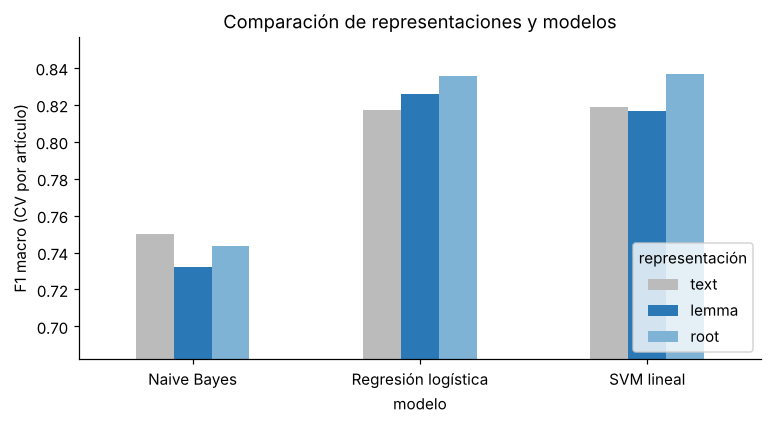

In [18]:
pivot = comparativa.pivot(index="modelo", columns="representación", values="f1_macro")[["text", "lemma", "root"]]
ax = pivot.plot.bar(figsize=(8, 3.8), rot=0, color=["#bbb", "#2a78b5", "#7fb3d5"])
ax.set_ylim(pivot.values.min() - 0.05, pivot.values.max() + 0.02)
ax.set_ylabel("F1 macro (CV por artículo)"); ax.set_title("Comparación de representaciones y modelos")
ax.legend(title="representación", loc="lower right"); plt.show()

#### Ajuste de hiperparámetros

Sobre la mejor representación se ajusta el hiperparámetro principal del mejor
modelo y se prueba si añadir **bigramas** ayuda (p. ej. *granda ŝlemo*,
*nacia teamo*).

In [19]:
from sklearn.model_selection import GridSearchCV

mejor = comparativa.iloc[0]
REP = mejor["representación"]
X_txt = REPRESENTACIONES[REP]
modelo_base = candidate_models()[mejor["modelo"]]
param = {"Naive Bayes": {"clf__alpha": [0.01, 0.05, 0.1, 0.3, 1.0]},
         "Regresión logística": {"clf__C": [1, 3, 10, 30]},
         "SVM lineal": {"clf__C": [0.1, 0.3, 1, 3]}}[mejor["modelo"]]
param["tfidf__ngram_range"] = [(1, 1), (1, 2)]

busqueda = GridSearchCV(build_pipeline(modelo_base), param, scoring="f1_macro", cv=cv_grupos, n_jobs=-1)
busqueda.fit(X_txt, y, groups=grupos)
print(f"Modelo: {mejor['modelo']} · representación: {REP}")
print("Mejores hiperparámetros:", busqueda.best_params_, f"→ F1 macro CV = {busqueda.best_score_:.3f}")

Modelo: SVM lineal · representación: root
Mejores hiperparámetros: {'clf__C': 1, 'tfidf__ngram_range': (1, 1)} → F1 macro CV = 0.837


#### ¿Por qué agrupar por artículo? (fuga de información)

Misma configuración, evaluada con una validación cruzada **aleatoria** por párrafos:

In [20]:
cv_aleatoria = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
f1_aleatoria = cross_validate(busqueda.best_estimator_, X_txt, y, cv=cv_aleatoria,
                              scoring="f1_macro", n_jobs=-1)["test_score"].mean()
print(f"F1 macro con CV aleatoria por párrafo : {f1_aleatoria:.3f}  (optimista)")
print(f"F1 macro con CV agrupada por artículo : {busqueda.best_score_:.3f}  (realista)")

F1 macro con CV aleatoria por párrafo : 0.917  (optimista)
F1 macro con CV agrupada por artículo : 0.837  (realista)


### 3.3 Modelo final: entrenamiento y evaluación en test

In [21]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

# Partición 80/20 por artículo (la primera de las 5 particiones agrupadas ≈ 20 %)
idx_train, idx_test = next(cv_grupos.split(X_txt, y, grupos))
X_train = [X_txt[i] for i in idx_train]; X_test = [X_txt[i] for i in idx_test]
y_train, y_test = y[idx_train], y[idx_test]
print(f"train: {len(idx_train)} párrafos · test: {len(idx_test)} párrafos "
      f"({len(set(grupos[idx_test]))} artículos que el modelo nunca ha visto)")

modelo = clone(busqueda.best_estimator_)
# La SVM no da probabilidades: si gana, se calibra para poder usar predict_proba
if not hasattr(modelo.named_steps["clf"], "predict_proba"):
    modelo.steps[-1] = ("clf", CalibratedClassifierCV(modelo.named_steps["clf"], cv=3))
t0 = time.time()
modelo.fit(X_train, y_train)
print(f"Entrenado en {time.time() - t0:.2f} s")

y_pred = modelo.predict(X_test)
print(f"\nAccuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"F1 macro : {f1_score(y_test, y_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_pred, digits=3))

train: 1139 párrafos · test: 373 párrafos (131 artículos que el modelo nunca ha visto)


Entrenado en 0.05 s

Accuracy : 0.879
F1 macro : 0.871

              precision    recall  f1-score   support

       golfo      0.944     0.791     0.861        43
      rugbeo      0.990     0.752     0.855       137
      teniso      0.820     0.990     0.897       193

    accuracy                          0.879       373
   macro avg      0.918     0.844     0.871       373
weighted avg      0.897     0.879     0.877       373



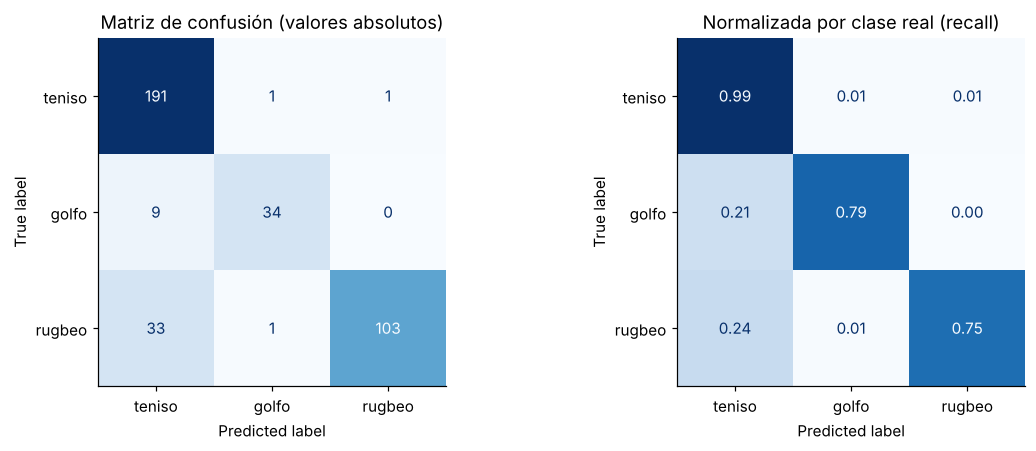

In [22]:
clases = list(TOPICS)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=clases), display_labels=clases).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusión (valores absolutos)")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=clases, normalize="true"),
                       display_labels=clases).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Normalizada por clase real (recall)")
plt.tight_layout(); plt.show()

### 3.4 Interpretación: palabras más discriminantes

Los pesos del modelo lineal muestran qué lemas empujan hacia cada clase. Es una
comprobación de que el modelo ha aprendido vocabulario temático y no artefactos.

In [23]:
modelo_interpretable = clone(busqueda.best_estimator_).fit(X_train, y_train)
top = top_features(modelo_interpretable, n=15)
display(pd.DataFrame(top)[clases])

,teniso,golfo,rugbeo
0,tenis,golfej,rugbe
1,tenisist,golfist,ofsajd
2,tenisej,golf,rugbeist
3,aparten,golfludist,rugby
4,raked,golfludant,rugbeteam
5,tablotenis,golflud,oponul
6,tenisistin,hotel,nations
7,subten,golfklub,modif
8,turnir,skotland,stadion
9,wimbledon,arbar,maĉ


### 3.5 Medición del ruido de etiquetado con el clasificador

Segunda medida del ruido de la Fase 1: con **predicciones fuera de la partición**
(*out-of-fold*, cada párrafo lo predice un modelo que no ha visto su artículo),
se cuentan los párrafos en los que el modelo **contradice la etiqueta con mucha
seguridad** (probabilidad > 0.8 para otra clase). Son los candidatos a párrafos
genéricos o mal etiquetados.

In [24]:
from sklearn.model_selection import cross_val_predict

modelo_oof = clone(modelo)
proba_oof = cross_val_predict(modelo_oof, X_txt, y, groups=grupos, cv=cv_grupos,
                              method="predict_proba", n_jobs=-1)
clases_oof = np.array(sorted(set(y)))
pred_oof = clases_oof[proba_oof.argmax(1)]
conf_oof = proba_oof.max(1)
df["pred_oof"], df["conf_oof"] = pred_oof, conf_oof
df["ruido_probable"] = (pred_oof != y) & (conf_oof > 0.8)

tabla_ruido = pd.DataFrame({
    "% contradice etiqueta (>0.8)": df.groupby("class")["ruido_probable"].mean() * 100,
    "% sin término de dominio": df.groupby("class")["sin_termino_de_dominio"].mean() * 100,
}).round(1).loc[clases]
display(tabla_ruido)
print(f"Estimación global de ruido (clasificador): {df['ruido_probable'].mean()*100:.1f} % de los párrafos")
print(f"Solo el {df.loc[df['ruido_probable'], 'sin_termino_de_dominio'].mean()*100:.0f} % de esos párrafos "
      "carece de términos de dominio: las dos medidas detectan cosas distintas (ver abajo).")
print("\nEjemplos de párrafos 'ruidosos':")
for _, r in df[df["ruido_probable"]].sample(6, random_state=SEED).iterrows():
    print(f" · etiqueta={r['class']:<8} predicción={r['pred_oof']:<8} ({r['conf_oof']:.2f}) [{r['title']}]")
    print(f"   {r['text'][:170]}")

,% contradice etiqueta (>0.8),% sin término de dominio
class,,
teniso,0.2,10.1
golfo,4.6,5.5
rugbeo,9.8,12.2


Estimación global de ruido (clasificador): 2.9 % de los párrafos
Solo el 41 % de esos párrafos carece de términos de dominio: las dos medidas detectan cosas distintas (ver abajo).

Ejemplos de párrafos 'ruidosos':
 · etiqueta=rugbeo   predicción=teniso   (0.80) [Ofsajdo]
   la avanulo estas antaŭ la hokeodisko, kiu estas reludata de defendanto
 · etiqueta=rugbeo   predicción=teniso   (0.95) [Ofsajdo]
   Laŭ FIFA-regularo (laste ŝanĝita en julio 2005 ofsajda delikto okazas, se ludanto en ofsajda pozicio - laŭ prijuĝo de la matĉestro - aktive enmiksiĝas en la ludado per
 · etiqueta=rugbeo   predicción=teniso   (0.85) [Ofsajdo]
   interago en la ludado - se li tuŝas aŭ ludas la pilkon post pasigo aŭ tuŝo de samteamano.
 · etiqueta=rugbeo   predicción=teniso   (0.97) [Ofsajdo]
   Ofsajdo en glacihokeo okazas - laŭ regulo 450/ 451 de la Internacia Glacihokea Federacio (IIHF) - se unu aŭ pluraj atakantaj ludantoj estas ludopretaj en la oponula defen
 · etiqueta=rugbeo   predicción=teniso   (

La medida heurística (sin términos de dominio) es mucho más alta porque la
lista de raíces es corta: marca como "genérico" cualquier párrafo que use otro
vocabulario. El clasificador es más fino. Al revisar sus ejemplos se ven dos
tipos de "errores":

1. **Ruido real del etiquetado**: párrafos de biografía, política o historia
   de un club que no hablan del deporte.
2. **Vocabulario compartido**: párrafos sobre torneos, olimpiadas, ciudades o
   países que podrían ser de cualquiera de los tres deportes.

¿Eliminar estos párrafos? Se ha decidido **no** hacerlo en el conjunto de test
(sería evaluar el modelo con datos elegidos por el propio modelo), pero sí se
comprueba qué pasa si se entrenan sin ellos:

In [25]:
mascara_train_limpio = ~df["ruido_probable"].values[idx_train]
modelo_limpio = clone(modelo).fit([X_train[i] for i in np.where(mascara_train_limpio)[0]],
                                  y_train[mascara_train_limpio])
print(f"F1 macro en test, entrenando con todo        : {f1_score(y_test, y_pred, average='macro'):.3f}")
print(f"F1 macro en test, entrenando sin párrafos ruidosos: "
      f"{f1_score(y_test, modelo_limpio.predict(X_test), average='macro'):.3f}")

F1 macro en test, entrenando con todo        : 0.871
F1 macro en test, entrenando sin párrafos ruidosos: 0.857


### 3.6 ¿El modelo solo mira el nombre del deporte?

Los párrafos del buscador se eligieron precisamente porque contienen la palabra
del deporte (*tenis-, golf-, rugbe-*). Un modelo podría aprobar solo con eso.
Para comprobarlo, se **eliminan de los textos todas las palabras que empiezan
por esas raíces** y se repite la validación cruzada.

In [26]:
sin_nombre = re.compile(r"\b(tenis|golf|rugbe)\S*", re.IGNORECASE)
X_sin_nombre = [re.sub(r"\s+", " ", sin_nombre.sub(" ", t)).strip() for t in X_txt]
f1_sin_nombre = cross_validate(clone(busqueda.best_estimator_), X_sin_nombre, y, groups=grupos,
                               cv=cv_grupos, scoring="f1_macro", n_jobs=-1)["test_score"].mean()
print(f"F1 macro CV con todas las palabras           : {busqueda.best_score_:.3f}")
print(f"F1 macro CV sin las palabras tenis/golf/rugbe: {f1_sin_nombre:.3f}")

F1 macro CV con todas las palabras           : 0.837
F1 macro CV sin las palabras tenis/golf/rugbe: 0.657


### 3.7 Modelo final con todos los datos

Para clasificar páginas web se reentrena el modelo con **todo** el dataset
(la evaluación ya se ha hecho con la partición de test).

In [27]:
modelo_final = clone(modelo).fit(X_txt, y)


def clasificar_texto(texto):
    proba = modelo_final.predict_proba([" ".join(doc_to_features(nlp(texto), REP))])[0]
    return {str(c): round(float(p), 3) for c, p in zip(modelo_final.classes_, proba)}


for frase in ["Ŝi venkis en la finalo de Wimbledon post tri setoj kontraŭ la unua en la mondo.",
              "Li bezonis nur kvar batojn por la dek-oka truo kaj gajnis la Masters-turniron.",
              "La nacia teamo de Nov-Zelando gajnis la mondan pokalon post fortega skramo."]:
    print(clasificar_texto(frase), "←", frase)

{'golfo': 0.011, 'rugbeo': 0.095, 'teniso': 0.894} ← Ŝi venkis en la finalo de Wimbledon post tri setoj kontraŭ la unua en la mondo.
{'golfo': 0.447, 'rugbeo': 0.018, 'teniso': 0.535} ← Li bezonis nur kvar batojn por la dek-oka truo kaj gajnis la Masters-turniron.
{'golfo': 0.02, 'rugbeo': 0.213, 'teniso': 0.767} ← La nacia teamo de Nov-Zelando gajnis la mondan pokalon post fortega skramo.


## 4. Clasificación de páginas web

Se eligen páginas **que no están en el dataset** (se comprueba abajo) y se
obtienen mediante *web scraping* de la **página HTML** con `requests` +
`BeautifulSoup` (no con el API): se eliminan `script`, `style`, tablas,
navegación, referencias y cajas de información, y se extraen los párrafos `<p>`,
que se limpian con la misma función que el dataset.

* **Tenis**: una noticia de **Vikinovaĵoj** (otra web, no Vikipedio) sobre
  Coco Gauff ganando el US Open.
* **Golf** y **rugby**: dos artículos de Vikipedio reservados (`HOLDOUT_TITLES`)
  y excluidos del dataset: *Golfejo* (campo de golf) y *Rugbea Monda Pokalo*
  (Copa del Mundo de rugby).
* **Pádel**: el artículo *Padelo (sporto)*. No hay clase de pádel, así que se
  mira a qué deporte lo acerca el modelo (lo esperable es el tenis).

**Robustez**: si una web falla (sin conexión, error HTTP, cambio de formato),
se usa una copia de respaldo publicada en el repositorio; si eso también falla,
esa página se omite con un aviso, pero el cuaderno sigue.

In [28]:
PAGINAS = {
    "https://eo.wikinews.org/wiki/Usona_tenisisto_Coco_Gauff_gajnis_la_tenisturniron_US_Open": "teniso",
    "https://eo.wikipedia.org/wiki/Golfejo": "golfo",
    "https://eo.wikipedia.org/wiki/Rugbea_Monda_Pokalo": "rugbeo",
    "https://eo.wikipedia.org/wiki/Padelo_(sporto)": "(pádel: sin clase)",
}
titulos_dataset = set(df["title"])
for url in PAGINAS:
    titulo = requests.utils.unquote(url.rsplit("/", 1)[1]).replace("_", " ")
    print(f"{titulo:<12} ¿está en el dataset? {'SÍ ⚠️' if titulo in titulos_dataset else 'no ✅'}")

respaldo = None


def obtener_parrafos(url):
    global respaldo
    html = fetch_html(url)
    if html:
        parrafos = html_to_paragraphs(html)
        if parrafos:
            return parrafos, "web en vivo"
    if respaldo is None:  # se descarga una sola vez
        try:
            respaldo = requests.get(URL_WEB_SNAPSHOT, timeout=20).json()
        except Exception as exc:
            print(f"  [aviso] tampoco hay copia de respaldo: {type(exc).__name__}")
            respaldo = {}
    return respaldo.get(url, []), "copia de respaldo"

Usona tenisisto Coco Gauff gajnis la tenisturniron US Open ¿está en el dataset? no ✅
Golfejo      ¿está en el dataset? no ✅
Rugbea Monda Pokalo ¿está en el dataset? no ✅
Padelo (sporto) ¿está en el dataset? no ✅


In [29]:
resultados = []
detalle = {}
for url, esperado in PAGINAS.items():
    parrafos, origen = obtener_parrafos(url)
    nombre = url.rsplit("/", 1)[1].replace("_", " ")
    if not parrafos:
        print(f"[omitida] {nombre}: no se pudo obtener texto")
        continue
    X_web = [" ".join(doc_to_features(d, REP)) for d in nlp.pipe(parrafos)]
    proba_par = modelo_final.predict_proba(X_web)
    proba_pag = proba_par.mean(axis=0)   # probabilidad de la página = media de sus párrafos
    detalle[nombre] = pd.DataFrame(proba_par, columns=modelo_final.classes_).assign(
        texto=[p[:80] + "…" for p in parrafos])
    fila = {"página": nombre, "origen": origen, "párrafos": len(parrafos), "esperada": esperado}
    fila.update({c: p for c, p in zip(modelo_final.classes_, proba_pag)})
    fila["predicción"] = modelo_final.classes_[proba_pag.argmax()]
    resultados.append(fila)

tabla_web = pd.DataFrame(resultados).set_index("página")
display(tabla_web.style.format({c: "{:.1%}" for c in clases})
        .background_gradient(subset=clases, cmap="Greens", axis=1))

  [aviso] no se pudo descargar https://eo.wikinews.org/wiki/Usona_tenisisto_Coco_Gauff_gajnis_la_tenisturniron_US_Open: ProxyError


  [aviso] no se pudo descargar https://eo.wikipedia.org/wiki/Golfejo: ProxyError
  [aviso] no se pudo descargar https://eo.wikipedia.org/wiki/Rugbea_Monda_Pokalo: ProxyError
  [aviso] no se pudo descargar https://eo.wikipedia.org/wiki/Padelo_(sporto): ProxyError


,origen,párrafos,esperada,golfo,rugbeo,teniso,predicción
página,,,,,,,
Usona tenisisto Coco Gauff gajnis la tenisturniron US Open,copia de respaldo,5,teniso,2.5%,3.5%,93.9%,teniso
Golfejo,copia de respaldo,4,golfo,99.2%,0.4%,0.4%,golfo
Rugbea Monda Pokalo,copia de respaldo,2,rugbeo,0.4%,97.7%,1.9%,rugbeo
Padelo (sporto),copia de respaldo,1,(pádel: sin clase),0.0%,0.4%,99.6%,teniso


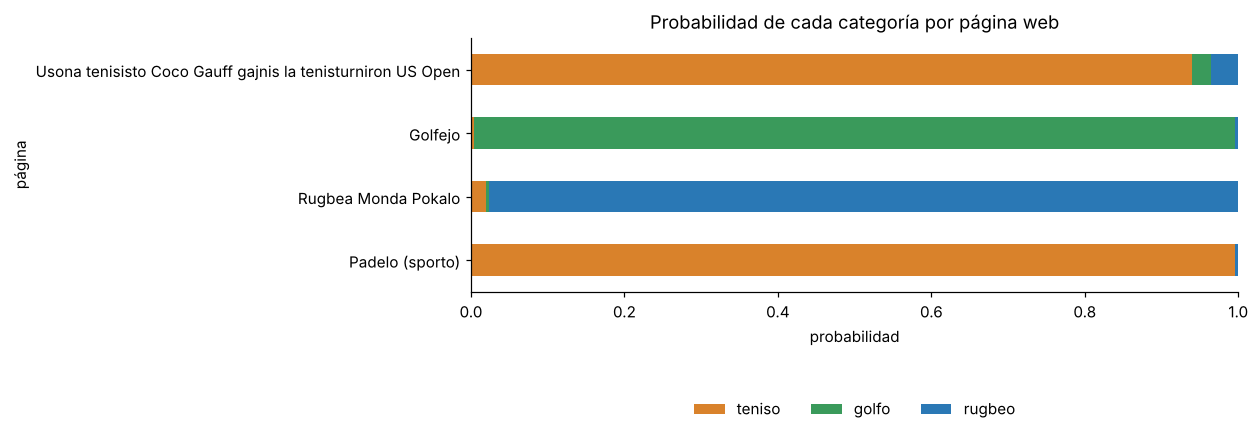

In [30]:
if len(tabla_web):
    ax = tabla_web[clases].plot.barh(stacked=True, figsize=(9, 0.6 + 0.6 * len(tabla_web)),
                                     color=[COLORES[c] for c in clases])
    ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("probabilidad")
    ax.set_title("Probabilidad de cada categoría por página web")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.55), ncol=3, frameon=False)
    plt.show()

**Probabilidad de la página = media de las probabilidades de sus párrafos.**
Se probó también a clasificar la página entera como un único documento, pero
Naive Bayes multiplica la evidencia de miles de palabras y la probabilidad se
satura a 0 % / 100 %, lo que no informa de la mezcla de temas. La media de
párrafos sí lo hace (y el modelo se entrenó precisamente con párrafos).

La clasificación **párrafo a párrafo** muestra qué partes de una página tiran
hacia cada categoría (aquí, la página de pádel):

In [31]:
for nombre in list(detalle)[-1:]:   # la página de pádel
    d = detalle[nombre]
    d["predicción"] = d[clases].idxmax(axis=1)
    print(f"{nombre}: reparto de párrafos →", d["predicción"].value_counts().to_dict())
    display(d[["texto"] + clases + ["predicción"]].head(10).style.format({c: "{:.2f}" for c in clases}))

Padelo (sporto): reparto de párrafos → {'teniso': 1}


,texto,teniso,golfo,rugbeo,predicción
0,"Padelo estas rakeda kaj pilka sporto, kiu estas ludata en enfermita kampo, aŭ ka…",1.00,0.00,0.00,teniso


## 5. Conclusiones

* **Dataset**: 1 512 párrafos de 730 artículos obtenidos automáticamente de
  Vikipedio, con un *script* reproducible y tolerante a fallos. La mayor
  dificultad ha sido la **falta de texto deportivo en Esperanto**: el pádel
  tuvo que sustituirse por el tenis y el golf se queda en 218 párrafos, por
  debajo de los 300 recomendados, aun combinando categoría y buscador. El ruido
  de etiquetado se ha medido de dos formas (≈18 % de párrafos de la categoría
  sin vocabulario deportivo; ≈3 % que el clasificador contradice con seguridad).
* **Modelo de NLP**: la regularidad del Esperanto permite un tokenizador,
  lematizador, etiquetador morfológico y gestor de stop-words basado en reglas,
  con un API como el de spaCy (`nlp(texto)` → `Doc` → `Token`), que acierta
  todos los tokens del *gold standard*.
* **Clasificación**: la representación por **raíces** (que da el modelo de NLP)
  es la mejor y reduce el vocabulario un 26 % respecto a la palabra sin
  procesar. El mejor modelo es la SVM lineal: F1 macro ≈0.84 en validación
  cruzada por artículo y ≈0.87 en el test. La validación aleatoria por
  párrafos daría ≈0.92, una cifra inflada por la fuga de información entre
  párrafos del mismo artículo.
* **Dependencia del nombre del deporte**: si se borran las palabras
  *tenis-/golf-/rugbe-*, el F1 cae a ≈0.66. El modelo se apoya mucho en ellas,
  en parte porque los párrafos del buscador se eligieron justo por contenerlas.
  Con más texto se podría aprender mejor el vocabulario propio de cada deporte
  (*seto, truo, skramo*...). Se ve también en las frases de ejemplo de 3.7: sin
  la palabra del deporte, el modelo tiende a decir **tenis**, la clase mayoritaria.
* **Web**: las tres páginas reales se clasifican bien con mucha seguridad
  (la noticia de Vikinovaĵoj, *Golfejo* y *Rugbea Monda Pokalo*). La página de
  **pádel** se asigna al **tenis** (≈100 %), lo cual es lógico: el texto lo
  describe como "una mezcla de tenis y squash" y habla de raqueta y pelota de tenis.

**Limitaciones y mejoras posibles**:

* Poco texto de golf y rugby, y desbalanceo hacia el tenis. Se podrían añadir
  otras fuentes en Esperanto (prensa, foros) o artículos traducidos.
* Ruido conocido: el artículo *Ofsajdo* (fuera de juego), en la categoría de
  rugby, habla también de fútbol y hockey sobre hielo.
* El léxico cerrado no es exhaustivo y las reglas de participios generan algún
  falso positivo (*konstanta*), que se corrige con una lista de excepciones.
* El *gold standard* de la Fase 2 es pequeño (10 frases); un 100 % en él no
  significa que el modelo no se equivoque en textos reales.